# Kaggle / cat-only Score-SDE with training_power presets
Train from scratch on **CIFAR-10 cats only** using the authors' DDPM++ / continuous VP architecture from Song et al., ICLR 2021. This is a **compute-budget adaptation**, not the paper's full benchmark setup. Original model source is pinned and embedded. The 107.6M model that previously managed 2,194 updates in eight hours is not used here.

Run top to bottom in a fresh GPU runtime. The clock starts in the first code cell and includes dependency installation, downloads, authentication, calibration, training and final generation. Manual pauses between cells also consume the budget. The deadline is best-effort: a disconnect, an unusually long operation or slow storage can prevent completion or cause a small overrun. This notebook cannot reserve GPU access or bypass platform quotas.

The only training data are the 5,000 cats in the CIFAR-10 training split. The 1,000 test-split cats are used as held-out development monitoring data, never for gradient updates. Images remain 32x32. No pretrained weights are loaded by default. Better image quality is not guaranteed by a time preset.

## Kaggle presets
Edit `training_power` in the settings cell. Durations are total wall-clock targets, not minimum guaranteed training time. Kaggle quota must already be available. The notebook uses one GPU (`cuda:0`), including when multiple GPUs are visible.

| training_power | Wall budget | Base width | Residual blocks/resolution | Warm-up time ceiling | Warm-up update cap |
|---|---:|---:|---:|---:|---:|
| easy | 1.75 h (under 2 h) | 32 | 2 | 2 min | 200 |
| mid | 4 h | 64 | 2 | 3 min | 300 |
| high | 8 h | 64 | 4 | 4 min | 400 |
| very high | 10 h | 96 | 4 | 5 min | 500 |

All presets use effective batch 64, Adam peak lr 2e-4, FP16 training/FP32 loss and weights, EMA, GPU-resident cat data and a measured microbatch. Exact warm-up is calibrated and additionally limited to about 3% of projected training updates. Larger power increases capacity moderately rather than jumping back to 107.6M parameters.

The official Kaggle documentation describes a 12-hour Save & Run All execution window; account quota can be more restrictive. https://www.kaggle.com/docs/notebooks . Save/download `/kaggle/working` outputs before ending the session. No automatic access to an old session's files is assumed.

Verified parameter counts: easy = 2,474,787; mid = 9,864,771; high = 15,476,675; very high = 34,784,163. These are architecture counts, not measured GPU throughput or quality results.

In [1]:
# Start the total wall-clock budget BEFORE setup.
import time
NOTEBOOK_START = time.monotonic()
%pip -q install ml-collections matplotlib pillow

Note: you may need to restart the kernel to use updated packages.


In [2]:
# Embedded official source, Apache 2.0. No GitHub clone or CUDA extension build.
from pathlib import Path
import sys
OFFICIAL_COMMIT = "cb1f359f4aadf0ff9a5e122fe8fffc9451fd6e44"
SOURCE_FILES = {'LICENSE': '                                 Apache License\n                           Version 2.0, January 2004\n                        http://www.apache.org/licenses/\n\n   TERMS AND CONDITIONS FOR USE, REPRODUCTION, AND DISTRIBUTION\n\n   1. Definitions.\n\n      "License" shall mean the terms and conditions for use, reproduction,\n      and distribution as defined by Sections 1 through 9 of this document.\n\n      "Licensor" shall mean the copyright owner or entity authorized by\n      the copyright owner that is granting the License.\n\n      "Legal Entity" shall mean the union of the acting entity and all\n      other entities that control, are controlled by, or are under common\n      control with that entity. For the purposes of this definition,\n      "control" means (i) the power, direct or indirect, to cause the\n      direction or management of such entity, whether by contract or\n      otherwise, or (ii) ownership of fifty percent (50%) or more of the\n      outstanding shares, or (iii) beneficial ownership of such entity.\n\n      "You" (or "Your") shall mean an individual or Legal Entity\n      exercising permissions granted by this License.\n\n      "Source" form shall mean the preferred form for making modifications,\n      including but not limited to software source code, documentation\n      source, and configuration files.\n\n      "Object" form shall mean any form resulting from mechanical\n      transformation or translation of a Source form, including but\n      not limited to compiled object code, generated documentation,\n      and conversions to other media types.\n\n      "Work" shall mean the work of authorship, whether in Source or\n      Object form, made available under the License, as indicated by a\n      copyright notice that is included in or attached to the work\n      (an example is provided in the Appendix below).\n\n      "Derivative Works" shall mean any work, whether in Source or Object\n      form, that is based on (or derived from) the Work and for which the\n      editorial revisions, annotations, elaborations, or other modifications\n      represent, as a whole, an original work of authorship. For the purposes\n      of this License, Derivative Works shall not include works that remain\n      separable from, or merely link (or bind by name) to the interfaces of,\n      the Work and Derivative Works thereof.\n\n      "Contribution" shall mean any work of authorship, including\n      the original version of the Work and any modifications or additions\n      to that Work or Derivative Works thereof, that is intentionally\n      submitted to Licensor for inclusion in the Work by the copyright owner\n      or by an individual or Legal Entity authorized to submit on behalf of\n      the copyright owner. For the purposes of this definition, "submitted"\n      means any form of electronic, verbal, or written communication sent\n      to the Licensor or its representatives, including but not limited to\n      communication on electronic mailing lists, source code control systems,\n      and issue tracking systems that are managed by, or on behalf of, the\n      Licensor for the purpose of discussing and improving the Work, but\n      excluding communication that is conspicuously marked or otherwise\n      designated in writing by the copyright owner as "Not a Contribution."\n\n      "Contributor" shall mean Licensor and any individual or Legal Entity\n      on behalf of whom a Contribution has been received by Licensor and\n      subsequently incorporated within the Work.\n\n   2. Grant of Copyright License. Subject to the terms and conditions of\n      this License, each Contributor hereby grants to You a perpetual,\n      worldwide, non-exclusive, no-charge, royalty-free, irrevocable\n      copyright license to reproduce, prepare Derivative Works of,\n      publicly display, publicly perform, sublicense, and distribute the\n      Work and such Derivative Works in Source or Object form.\n\n   3. Grant of Patent License. Subject to the terms and conditions of\n      this License, each Contributor hereby grants to You a perpetual,\n      worldwide, non-exclusive, no-charge, royalty-free, irrevocable\n      (except as stated in this section) patent license to make, have made,\n      use, offer to sell, sell, import, and otherwise transfer the Work,\n      where such license applies only to those patent claims licensable\n      by such Contributor that are necessarily infringed by their\n      Contribution(s) alone or by combination of their Contribution(s)\n      with the Work to which such Contribution(s) was submitted. If You\n      institute patent litigation against any entity (including a\n      cross-claim or counterclaim in a lawsuit) alleging that the Work\n      or a Contribution incorporated within the Work constitutes direct\n      or contributory patent infringement, then any patent licenses\n      granted to You under this License for that Work shall terminate\n      as of the date such litigation is filed.\n\n   4. Redistribution. You may reproduce and distribute copies of the\n      Work or Derivative Works thereof in any medium, with or without\n      modifications, and in Source or Object form, provided that You\n      meet the following conditions:\n\n      (a) You must give any other recipients of the Work or\n          Derivative Works a copy of this License; and\n\n      (b) You must cause any modified files to carry prominent notices\n          stating that You changed the files; and\n\n      (c) You must retain, in the Source form of any Derivative Works\n          that You distribute, all copyright, patent, trademark, and\n          attribution notices from the Source form of the Work,\n          excluding those notices that do not pertain to any part of\n          the Derivative Works; and\n\n      (d) If the Work includes a "NOTICE" text file as part of its\n          distribution, then any Derivative Works that You distribute must\n          include a readable copy of the attribution notices contained\n          within such NOTICE file, excluding those notices that do not\n          pertain to any part of the Derivative Works, in at least one\n          of the following places: within a NOTICE text file distributed\n          as part of the Derivative Works; within the Source form or\n          documentation, if provided along with the Derivative Works; or,\n          within a display generated by the Derivative Works, if and\n          wherever such third-party notices normally appear. The contents\n          of the NOTICE file are for informational purposes only and\n          do not modify the License. You may add Your own attribution\n          notices within Derivative Works that You distribute, alongside\n          or as an addendum to the NOTICE text from the Work, provided\n          that such additional attribution notices cannot be construed\n          as modifying the License.\n\n      You may add Your own copyright statement to Your modifications and\n      may provide additional or different license terms and conditions\n      for use, reproduction, or distribution of Your modifications, or\n      for any such Derivative Works as a whole, provided Your use,\n      reproduction, and distribution of the Work otherwise complies with\n      the conditions stated in this License.\n\n   5. Submission of Contributions. Unless You explicitly state otherwise,\n      any Contribution intentionally submitted for inclusion in the Work\n      by You to the Licensor shall be under the terms and conditions of\n      this License, without any additional terms or conditions.\n      Notwithstanding the above, nothing herein shall supersede or modify\n      the terms of any separate license agreement you may have executed\n      with Licensor regarding such Contributions.\n\n   6. Trademarks. This License does not grant permission to use the trade\n      names, trademarks, service marks, or product names of the Licensor,\n      except as required for reasonable and customary use in describing the\n      origin of the Work and reproducing the content of the NOTICE file.\n\n   7. Disclaimer of Warranty. Unless required by applicable law or\n      agreed to in writing, Licensor provides the Work (and each\n      Contributor provides its Contributions) on an "AS IS" BASIS,\n      WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or\n      implied, including, without limitation, any warranties or conditions\n      of TITLE, NON-INFRINGEMENT, MERCHANTABILITY, or FITNESS FOR A\n      PARTICULAR PURPOSE. You are solely responsible for determining the\n      appropriateness of using or redistributing the Work and assume any\n      risks associated with Your exercise of permissions under this License.\n\n   8. Limitation of Liability. In no event and under no legal theory,\n      whether in tort (including negligence), contract, or otherwise,\n      unless required by applicable law (such as deliberate and grossly\n      negligent acts) or agreed to in writing, shall any Contributor be\n      liable to You for damages, including any direct, indirect, special,\n      incidental, or consequential damages of any character arising as a\n      result of this License or out of the use or inability to use the\n      Work (including but not limited to damages for loss of goodwill,\n      work stoppage, computer failure or malfunction, or any and all\n      other commercial damages or losses), even if such Contributor\n      has been advised of the possibility of such damages.\n\n   9. Accepting Warranty or Additional Liability. While redistributing\n      the Work or Derivative Works thereof, You may choose to offer,\n      and charge a fee for, acceptance of support, warranty, indemnity,\n      or other liability obligations and/or rights consistent with this\n      License. However, in accepting such obligations, You may act only\n      on Your own behalf and on Your sole responsibility, not on behalf\n      of any other Contributor, and only if You agree to indemnify,\n      defend, and hold each Contributor harmless for any liability\n      incurred by, or claims asserted against, such Contributor by reason\n      of your accepting any such warranty or additional liability.\n\n   END OF TERMS AND CONDITIONS\n\n   APPENDIX: How to apply the Apache License to your work.\n\n      To apply the Apache License to your work, attach the following\n      boilerplate notice, with the fields enclosed by brackets "[]"\n      replaced with your own identifying information. (Don\'t include\n      the brackets!)  The text should be enclosed in the appropriate\n      comment syntax for the file format. We also recommend that a\n      file or class name and description of purpose be included on the\n      same "printed page" as the copyright notice for easier\n      identification within third-party archives.\n\n   Copyright [yyyy] [name of copyright owner]\n\n   Licensed under the Apache License, Version 2.0 (the "License");\n   you may not use this file except in compliance with the License.\n   You may obtain a copy of the License at\n\n       http://www.apache.org/licenses/LICENSE-2.0\n\n   Unless required by applicable law or agreed to in writing, software\n   distributed under the License is distributed on an "AS IS" BASIS,\n   WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.\n   See the License for the specific language governing permissions and\n   limitations under the License.\n', 'sde_lib.py': '"""Abstract SDE classes, Reverse SDE, and VE/VP SDEs."""\nimport abc\nimport torch\nimport numpy as np\n\n\nclass SDE(abc.ABC):\n  """SDE abstract class. Functions are designed for a mini-batch of inputs."""\n\n  def __init__(self, N):\n    """Construct an SDE.\n\n    Args:\n      N: number of discretization time steps.\n    """\n    super().__init__()\n    self.N = N\n\n  @property\n  @abc.abstractmethod\n  def T(self):\n    """End time of the SDE."""\n    pass\n\n  @abc.abstractmethod\n  def sde(self, x, t):\n    pass\n\n  @abc.abstractmethod\n  def marginal_prob(self, x, t):\n    """Parameters to determine the marginal distribution of the SDE, $p_t(x)$."""\n    pass\n\n  @abc.abstractmethod\n  def prior_sampling(self, shape):\n    """Generate one sample from the prior distribution, $p_T(x)$."""\n    pass\n\n  @abc.abstractmethod\n  def prior_logp(self, z):\n    """Compute log-density of the prior distribution.\n\n    Useful for computing the log-likelihood via probability flow ODE.\n\n    Args:\n      z: latent code\n    Returns:\n      log probability density\n    """\n    pass\n\n  def discretize(self, x, t):\n    """Discretize the SDE in the form: x_{i+1} = x_i + f_i(x_i) + G_i z_i.\n\n    Useful for reverse diffusion sampling and probabiliy flow sampling.\n    Defaults to Euler-Maruyama discretization.\n\n    Args:\n      x: a torch tensor\n      t: a torch float representing the time step (from 0 to `self.T`)\n\n    Returns:\n      f, G\n    """\n    dt = 1 / self.N\n    drift, diffusion = self.sde(x, t)\n    f = drift * dt\n    G = diffusion * torch.sqrt(torch.tensor(dt, device=t.device))\n    return f, G\n\n  def reverse(self, score_fn, probability_flow=False):\n    """Create the reverse-time SDE/ODE.\n\n    Args:\n      score_fn: A time-dependent score-based model that takes x and t and returns the score.\n      probability_flow: If `True`, create the reverse-time ODE used for probability flow sampling.\n    """\n    N = self.N\n    T = self.T\n    sde_fn = self.sde\n    discretize_fn = self.discretize\n\n    # Build the class for reverse-time SDE.\n    class RSDE(self.__class__):\n      def __init__(self):\n        self.N = N\n        self.probability_flow = probability_flow\n\n      @property\n      def T(self):\n        return T\n\n      def sde(self, x, t):\n        """Create the drift and diffusion functions for the reverse SDE/ODE."""\n        drift, diffusion = sde_fn(x, t)\n        score = score_fn(x, t)\n        drift = drift - diffusion[:, None, None, None] ** 2 * score * (0.5 if self.probability_flow else 1.)\n        # Set the diffusion function to zero for ODEs.\n        diffusion = 0. if self.probability_flow else diffusion\n        return drift, diffusion\n\n      def discretize(self, x, t):\n        """Create discretized iteration rules for the reverse diffusion sampler."""\n        f, G = discretize_fn(x, t)\n        rev_f = f - G[:, None, None, None] ** 2 * score_fn(x, t) * (0.5 if self.probability_flow else 1.)\n        rev_G = torch.zeros_like(G) if self.probability_flow else G\n        return rev_f, rev_G\n\n    return RSDE()\n\n\nclass VPSDE(SDE):\n  def __init__(self, beta_min=0.1, beta_max=20, N=1000):\n    """Construct a Variance Preserving SDE.\n\n    Args:\n      beta_min: value of beta(0)\n      beta_max: value of beta(1)\n      N: number of discretization steps\n    """\n    super().__init__(N)\n    self.beta_0 = beta_min\n    self.beta_1 = beta_max\n    self.N = N\n    self.discrete_betas = torch.linspace(beta_min / N, beta_max / N, N)\n    self.alphas = 1. - self.discrete_betas\n    self.alphas_cumprod = torch.cumprod(self.alphas, dim=0)\n    self.sqrt_alphas_cumprod = torch.sqrt(self.alphas_cumprod)\n    self.sqrt_1m_alphas_cumprod = torch.sqrt(1. - self.alphas_cumprod)\n\n  @property\n  def T(self):\n    return 1\n\n  def sde(self, x, t):\n    beta_t = self.beta_0 + t * (self.beta_1 - self.beta_0)\n    drift = -0.5 * beta_t[:, None, None, None] * x\n    diffusion = torch.sqrt(beta_t)\n    return drift, diffusion\n\n  def marginal_prob(self, x, t):\n    log_mean_coeff = -0.25 * t ** 2 * (self.beta_1 - self.beta_0) - 0.5 * t * self.beta_0\n    mean = torch.exp(log_mean_coeff[:, None, None, None]) * x\n    std = torch.sqrt(1. - torch.exp(2. * log_mean_coeff))\n    return mean, std\n\n  def prior_sampling(self, shape):\n    return torch.randn(*shape)\n\n  def prior_logp(self, z):\n    shape = z.shape\n    N = np.prod(shape[1:])\n    logps = -N / 2. * np.log(2 * np.pi) - torch.sum(z ** 2, dim=(1, 2, 3)) / 2.\n    return logps\n\n  def discretize(self, x, t):\n    """DDPM discretization."""\n    timestep = (t * (self.N - 1) / self.T).long()\n    beta = self.discrete_betas.to(x.device)[timestep]\n    alpha = self.alphas.to(x.device)[timestep]\n    sqrt_beta = torch.sqrt(beta)\n    f = torch.sqrt(alpha)[:, None, None, None] * x - x\n    G = sqrt_beta\n    return f, G\n\n\nclass subVPSDE(SDE):\n  def __init__(self, beta_min=0.1, beta_max=20, N=1000):\n    """Construct the sub-VP SDE that excels at likelihoods.\n\n    Args:\n      beta_min: value of beta(0)\n      beta_max: value of beta(1)\n      N: number of discretization steps\n    """\n    super().__init__(N)\n    self.beta_0 = beta_min\n    self.beta_1 = beta_max\n    self.N = N\n\n  @property\n  def T(self):\n    return 1\n\n  def sde(self, x, t):\n    beta_t = self.beta_0 + t * (self.beta_1 - self.beta_0)\n    drift = -0.5 * beta_t[:, None, None, None] * x\n    discount = 1. - torch.exp(-2 * self.beta_0 * t - (self.beta_1 - self.beta_0) * t ** 2)\n    diffusion = torch.sqrt(beta_t * discount)\n    return drift, diffusion\n\n  def marginal_prob(self, x, t):\n    log_mean_coeff = -0.25 * t ** 2 * (self.beta_1 - self.beta_0) - 0.5 * t * self.beta_0\n    mean = torch.exp(log_mean_coeff)[:, None, None, None] * x\n    std = 1 - torch.exp(2. * log_mean_coeff)\n    return mean, std\n\n  def prior_sampling(self, shape):\n    return torch.randn(*shape)\n\n  def prior_logp(self, z):\n    shape = z.shape\n    N = np.prod(shape[1:])\n    return -N / 2. * np.log(2 * np.pi) - torch.sum(z ** 2, dim=(1, 2, 3)) / 2.\n\n\nclass VESDE(SDE):\n  def __init__(self, sigma_min=0.01, sigma_max=50, N=1000):\n    """Construct a Variance Exploding SDE.\n\n    Args:\n      sigma_min: smallest sigma.\n      sigma_max: largest sigma.\n      N: number of discretization steps\n    """\n    super().__init__(N)\n    self.sigma_min = sigma_min\n    self.sigma_max = sigma_max\n    self.discrete_sigmas = torch.exp(torch.linspace(np.log(self.sigma_min), np.log(self.sigma_max), N))\n    self.N = N\n\n  @property\n  def T(self):\n    return 1\n\n  def sde(self, x, t):\n    sigma = self.sigma_min * (self.sigma_max / self.sigma_min) ** t\n    drift = torch.zeros_like(x)\n    diffusion = sigma * torch.sqrt(torch.tensor(2 * (np.log(self.sigma_max) - np.log(self.sigma_min)),\n                                                device=t.device))\n    return drift, diffusion\n\n  def marginal_prob(self, x, t):\n    std = self.sigma_min * (self.sigma_max / self.sigma_min) ** t\n    mean = x\n    return mean, std\n\n  def prior_sampling(self, shape):\n    return torch.randn(*shape) * self.sigma_max\n\n  def prior_logp(self, z):\n    shape = z.shape\n    N = np.prod(shape[1:])\n    return -N / 2. * np.log(2 * np.pi * self.sigma_max ** 2) - torch.sum(z ** 2, dim=(1, 2, 3)) / (2 * self.sigma_max ** 2)\n\n  def discretize(self, x, t):\n    """SMLD(NCSN) discretization."""\n    timestep = (t * (self.N - 1) / self.T).long()\n    sigma = self.discrete_sigmas.to(t.device)[timestep]\n    adjacent_sigma = torch.where(timestep == 0, torch.zeros_like(t),\n                                 self.discrete_sigmas[timestep - 1].to(t.device))\n    f = torch.zeros_like(x)\n    G = torch.sqrt(sigma ** 2 - adjacent_sigma ** 2)\n    return f, G', 'models/__init__.py': '# coding=utf-8\n# Copyright 2020 The Google Research Authors.\n#\n# Licensed under the Apache License, Version 2.0 (the "License");\n# you may not use this file except in compliance with the License.\n# You may obtain a copy of the License at\n#\n#     http://www.apache.org/licenses/LICENSE-2.0\n#\n# Unless required by applicable law or agreed to in writing, software\n# distributed under the License is distributed on an "AS IS" BASIS,\n# WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.\n# See the License for the specific language governing permissions and\n# limitations under the License.\n\n', 'models/ncsnpp.py': '# coding=utf-8\n# Copyright 2020 The Google Research Authors.\n#\n# Licensed under the Apache License, Version 2.0 (the "License");\n# you may not use this file except in compliance with the License.\n# You may obtain a copy of the License at\n#\n#     http://www.apache.org/licenses/LICENSE-2.0\n#\n# Unless required by applicable law or agreed to in writing, software\n# distributed under the License is distributed on an "AS IS" BASIS,\n# WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.\n# See the License for the specific language governing permissions and\n# limitations under the License.\n\n# pylint: skip-file\n\nfrom . import utils, layers, layerspp, normalization\nimport torch.nn as nn\nimport functools\nimport torch\nimport numpy as np\n\nResnetBlockDDPM = layerspp.ResnetBlockDDPMpp\nResnetBlockBigGAN = layerspp.ResnetBlockBigGANpp\nCombine = layerspp.Combine\nconv3x3 = layerspp.conv3x3\nconv1x1 = layerspp.conv1x1\nget_act = layers.get_act\nget_normalization = normalization.get_normalization\ndefault_initializer = layers.default_init\n\n\n@utils.register_model(name=\'ncsnpp\')\nclass NCSNpp(nn.Module):\n  """NCSN++ model"""\n\n  def __init__(self, config):\n    super().__init__()\n    self.config = config\n    self.act = act = get_act(config)\n    self.register_buffer(\'sigmas\', torch.tensor(utils.get_sigmas(config)))\n\n    self.nf = nf = config.model.nf\n    ch_mult = config.model.ch_mult\n    self.num_res_blocks = num_res_blocks = config.model.num_res_blocks\n    self.attn_resolutions = attn_resolutions = config.model.attn_resolutions\n    dropout = config.model.dropout\n    resamp_with_conv = config.model.resamp_with_conv\n    self.num_resolutions = num_resolutions = len(ch_mult)\n    self.all_resolutions = all_resolutions = [config.data.image_size // (2 ** i) for i in range(num_resolutions)]\n\n    self.conditional = conditional = config.model.conditional  # noise-conditional\n    fir = config.model.fir\n    fir_kernel = config.model.fir_kernel\n    self.skip_rescale = skip_rescale = config.model.skip_rescale\n    self.resblock_type = resblock_type = config.model.resblock_type.lower()\n    self.progressive = progressive = config.model.progressive.lower()\n    self.progressive_input = progressive_input = config.model.progressive_input.lower()\n    self.embedding_type = embedding_type = config.model.embedding_type.lower()\n    init_scale = config.model.init_scale\n    assert progressive in [\'none\', \'output_skip\', \'residual\']\n    assert progressive_input in [\'none\', \'input_skip\', \'residual\']\n    assert embedding_type in [\'fourier\', \'positional\']\n    combine_method = config.model.progressive_combine.lower()\n    combiner = functools.partial(Combine, method=combine_method)\n\n    modules = []\n    # timestep/noise_level embedding; only for continuous training\n    if embedding_type == \'fourier\':\n      # Gaussian Fourier features embeddings.\n      assert config.training.continuous, "Fourier features are only used for continuous training."\n\n      modules.append(layerspp.GaussianFourierProjection(\n        embedding_size=nf, scale=config.model.fourier_scale\n      ))\n      embed_dim = 2 * nf\n\n    elif embedding_type == \'positional\':\n      embed_dim = nf\n\n    else:\n      raise ValueError(f\'embedding type {embedding_type} unknown.\')\n\n    if conditional:\n      modules.append(nn.Linear(embed_dim, nf * 4))\n      modules[-1].weight.data = default_initializer()(modules[-1].weight.shape)\n      nn.init.zeros_(modules[-1].bias)\n      modules.append(nn.Linear(nf * 4, nf * 4))\n      modules[-1].weight.data = default_initializer()(modules[-1].weight.shape)\n      nn.init.zeros_(modules[-1].bias)\n\n    AttnBlock = functools.partial(layerspp.AttnBlockpp,\n                                  init_scale=init_scale,\n                                  skip_rescale=skip_rescale)\n\n    Upsample = functools.partial(layerspp.Upsample,\n                                 with_conv=resamp_with_conv, fir=fir, fir_kernel=fir_kernel)\n\n    if progressive == \'output_skip\':\n      self.pyramid_upsample = layerspp.Upsample(fir=fir, fir_kernel=fir_kernel, with_conv=False)\n    elif progressive == \'residual\':\n      pyramid_upsample = functools.partial(layerspp.Upsample,\n                                           fir=fir, fir_kernel=fir_kernel, with_conv=True)\n\n    Downsample = functools.partial(layerspp.Downsample,\n                                   with_conv=resamp_with_conv, fir=fir, fir_kernel=fir_kernel)\n\n    if progressive_input == \'input_skip\':\n      self.pyramid_downsample = layerspp.Downsample(fir=fir, fir_kernel=fir_kernel, with_conv=False)\n    elif progressive_input == \'residual\':\n      pyramid_downsample = functools.partial(layerspp.Downsample,\n                                             fir=fir, fir_kernel=fir_kernel, with_conv=True)\n\n    if resblock_type == \'ddpm\':\n      ResnetBlock = functools.partial(ResnetBlockDDPM,\n                                      act=act,\n                                      dropout=dropout,\n                                      init_scale=init_scale,\n                                      skip_rescale=skip_rescale,\n                                      temb_dim=nf * 4)\n\n    elif resblock_type == \'biggan\':\n      ResnetBlock = functools.partial(ResnetBlockBigGAN,\n                                      act=act,\n                                      dropout=dropout,\n                                      fir=fir,\n                                      fir_kernel=fir_kernel,\n                                      init_scale=init_scale,\n                                      skip_rescale=skip_rescale,\n                                      temb_dim=nf * 4)\n\n    else:\n      raise ValueError(f\'resblock type {resblock_type} unrecognized.\')\n\n    # Downsampling block\n\n    channels = config.data.num_channels\n    if progressive_input != \'none\':\n      input_pyramid_ch = channels\n\n    modules.append(conv3x3(channels, nf))\n    hs_c = [nf]\n\n    in_ch = nf\n    for i_level in range(num_resolutions):\n      # Residual blocks for this resolution\n      for i_block in range(num_res_blocks):\n        out_ch = nf * ch_mult[i_level]\n        modules.append(ResnetBlock(in_ch=in_ch, out_ch=out_ch))\n        in_ch = out_ch\n\n        if all_resolutions[i_level] in attn_resolutions:\n          modules.append(AttnBlock(channels=in_ch))\n        hs_c.append(in_ch)\n\n      if i_level != num_resolutions - 1:\n        if resblock_type == \'ddpm\':\n          modules.append(Downsample(in_ch=in_ch))\n        else:\n          modules.append(ResnetBlock(down=True, in_ch=in_ch))\n\n        if progressive_input == \'input_skip\':\n          modules.append(combiner(dim1=input_pyramid_ch, dim2=in_ch))\n          if combine_method == \'cat\':\n            in_ch *= 2\n\n        elif progressive_input == \'residual\':\n          modules.append(pyramid_downsample(in_ch=input_pyramid_ch, out_ch=in_ch))\n          input_pyramid_ch = in_ch\n\n        hs_c.append(in_ch)\n\n    in_ch = hs_c[-1]\n    modules.append(ResnetBlock(in_ch=in_ch))\n    modules.append(AttnBlock(channels=in_ch))\n    modules.append(ResnetBlock(in_ch=in_ch))\n\n    pyramid_ch = 0\n    # Upsampling block\n    for i_level in reversed(range(num_resolutions)):\n      for i_block in range(num_res_blocks + 1):\n        out_ch = nf * ch_mult[i_level]\n        modules.append(ResnetBlock(in_ch=in_ch + hs_c.pop(),\n                                   out_ch=out_ch))\n        in_ch = out_ch\n\n      if all_resolutions[i_level] in attn_resolutions:\n        modules.append(AttnBlock(channels=in_ch))\n\n      if progressive != \'none\':\n        if i_level == num_resolutions - 1:\n          if progressive == \'output_skip\':\n            modules.append(nn.GroupNorm(num_groups=min(in_ch // 4, 32),\n                                        num_channels=in_ch, eps=1e-6))\n            modules.append(conv3x3(in_ch, channels, init_scale=init_scale))\n            pyramid_ch = channels\n          elif progressive == \'residual\':\n            modules.append(nn.GroupNorm(num_groups=min(in_ch // 4, 32),\n                                        num_channels=in_ch, eps=1e-6))\n            modules.append(conv3x3(in_ch, in_ch, bias=True))\n            pyramid_ch = in_ch\n          else:\n            raise ValueError(f\'{progressive} is not a valid name.\')\n        else:\n          if progressive == \'output_skip\':\n            modules.append(nn.GroupNorm(num_groups=min(in_ch // 4, 32),\n                                        num_channels=in_ch, eps=1e-6))\n            modules.append(conv3x3(in_ch, channels, bias=True, init_scale=init_scale))\n            pyramid_ch = channels\n          elif progressive == \'residual\':\n            modules.append(pyramid_upsample(in_ch=pyramid_ch, out_ch=in_ch))\n            pyramid_ch = in_ch\n          else:\n            raise ValueError(f\'{progressive} is not a valid name\')\n\n      if i_level != 0:\n        if resblock_type == \'ddpm\':\n          modules.append(Upsample(in_ch=in_ch))\n        else:\n          modules.append(ResnetBlock(in_ch=in_ch, up=True))\n\n    assert not hs_c\n\n    if progressive != \'output_skip\':\n      modules.append(nn.GroupNorm(num_groups=min(in_ch // 4, 32),\n                                  num_channels=in_ch, eps=1e-6))\n      modules.append(conv3x3(in_ch, channels, init_scale=init_scale))\n\n    self.all_modules = nn.ModuleList(modules)\n\n  def forward(self, x, time_cond):\n    # timestep/noise_level embedding; only for continuous training\n    modules = self.all_modules\n    m_idx = 0\n    if self.embedding_type == \'fourier\':\n      # Gaussian Fourier features embeddings.\n      used_sigmas = time_cond\n      temb = modules[m_idx](torch.log(used_sigmas))\n      m_idx += 1\n\n    elif self.embedding_type == \'positional\':\n      # Sinusoidal positional embeddings.\n      timesteps = time_cond\n      used_sigmas = self.sigmas[time_cond.long()]\n      temb = layers.get_timestep_embedding(timesteps, self.nf)\n\n    else:\n      raise ValueError(f\'embedding type {self.embedding_type} unknown.\')\n\n    if self.conditional:\n      temb = modules[m_idx](temb)\n      m_idx += 1\n      temb = modules[m_idx](self.act(temb))\n      m_idx += 1\n    else:\n      temb = None\n\n    if not self.config.data.centered:\n      # If input data is in [0, 1]\n      x = 2 * x - 1.\n\n    # Downsampling block\n    input_pyramid = None\n    if self.progressive_input != \'none\':\n      input_pyramid = x\n\n    hs = [modules[m_idx](x)]\n    m_idx += 1\n    for i_level in range(self.num_resolutions):\n      # Residual blocks for this resolution\n      for i_block in range(self.num_res_blocks):\n        h = modules[m_idx](hs[-1], temb)\n        m_idx += 1\n        if h.shape[-1] in self.attn_resolutions:\n          h = modules[m_idx](h)\n          m_idx += 1\n\n        hs.append(h)\n\n      if i_level != self.num_resolutions - 1:\n        if self.resblock_type == \'ddpm\':\n          h = modules[m_idx](hs[-1])\n          m_idx += 1\n        else:\n          h = modules[m_idx](hs[-1], temb)\n          m_idx += 1\n\n        if self.progressive_input == \'input_skip\':\n          input_pyramid = self.pyramid_downsample(input_pyramid)\n          h = modules[m_idx](input_pyramid, h)\n          m_idx += 1\n\n        elif self.progressive_input == \'residual\':\n          input_pyramid = modules[m_idx](input_pyramid)\n          m_idx += 1\n          if self.skip_rescale:\n            input_pyramid = (input_pyramid + h) / np.sqrt(2.)\n          else:\n            input_pyramid = input_pyramid + h\n          h = input_pyramid\n\n        hs.append(h)\n\n    h = hs[-1]\n    h = modules[m_idx](h, temb)\n    m_idx += 1\n    h = modules[m_idx](h)\n    m_idx += 1\n    h = modules[m_idx](h, temb)\n    m_idx += 1\n\n    pyramid = None\n\n    # Upsampling block\n    for i_level in reversed(range(self.num_resolutions)):\n      for i_block in range(self.num_res_blocks + 1):\n        h = modules[m_idx](torch.cat([h, hs.pop()], dim=1), temb)\n        m_idx += 1\n\n      if h.shape[-1] in self.attn_resolutions:\n        h = modules[m_idx](h)\n        m_idx += 1\n\n      if self.progressive != \'none\':\n        if i_level == self.num_resolutions - 1:\n          if self.progressive == \'output_skip\':\n            pyramid = self.act(modules[m_idx](h))\n            m_idx += 1\n            pyramid = modules[m_idx](pyramid)\n            m_idx += 1\n          elif self.progressive == \'residual\':\n            pyramid = self.act(modules[m_idx](h))\n            m_idx += 1\n            pyramid = modules[m_idx](pyramid)\n            m_idx += 1\n          else:\n            raise ValueError(f\'{self.progressive} is not a valid name.\')\n        else:\n          if self.progressive == \'output_skip\':\n            pyramid = self.pyramid_upsample(pyramid)\n            pyramid_h = self.act(modules[m_idx](h))\n            m_idx += 1\n            pyramid_h = modules[m_idx](pyramid_h)\n            m_idx += 1\n            pyramid = pyramid + pyramid_h\n          elif self.progressive == \'residual\':\n            pyramid = modules[m_idx](pyramid)\n            m_idx += 1\n            if self.skip_rescale:\n              pyramid = (pyramid + h) / np.sqrt(2.)\n            else:\n              pyramid = pyramid + h\n            h = pyramid\n          else:\n            raise ValueError(f\'{self.progressive} is not a valid name\')\n\n      if i_level != 0:\n        if self.resblock_type == \'ddpm\':\n          h = modules[m_idx](h)\n          m_idx += 1\n        else:\n          h = modules[m_idx](h, temb)\n          m_idx += 1\n\n    assert not hs\n\n    if self.progressive == \'output_skip\':\n      h = pyramid\n    else:\n      h = self.act(modules[m_idx](h))\n      m_idx += 1\n      h = modules[m_idx](h)\n      m_idx += 1\n\n    assert m_idx == len(modules)\n    if self.config.model.scale_by_sigma:\n      used_sigmas = used_sigmas.reshape((x.shape[0], *([1] * len(x.shape[1:]))))\n      h = h / used_sigmas\n\n    return h\n', 'models/utils.py': '# coding=utf-8\n# Copyright 2020 The Google Research Authors.\n#\n# Licensed under the Apache License, Version 2.0 (the "License");\n# you may not use this file except in compliance with the License.\n# You may obtain a copy of the License at\n#\n#     http://www.apache.org/licenses/LICENSE-2.0\n#\n# Unless required by applicable law or agreed to in writing, software\n# distributed under the License is distributed on an "AS IS" BASIS,\n# WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.\n# See the License for the specific language governing permissions and\n# limitations under the License.\n\n"""All functions and modules related to model definition.\n"""\n\nimport torch\nimport sde_lib\nimport numpy as np\n\n\n_MODELS = {}\n\n\ndef register_model(cls=None, *, name=None):\n  """A decorator for registering model classes."""\n\n  def _register(cls):\n    if name is None:\n      local_name = cls.__name__\n    else:\n      local_name = name\n    if local_name in _MODELS:\n      raise ValueError(f\'Already registered model with name: {local_name}\')\n    _MODELS[local_name] = cls\n    return cls\n\n  if cls is None:\n    return _register\n  else:\n    return _register(cls)\n\n\ndef get_model(name):\n  return _MODELS[name]\n\n\ndef get_sigmas(config):\n  """Get sigmas --- the set of noise levels for SMLD from config files.\n  Args:\n    config: A ConfigDict object parsed from the config file\n  Returns:\n    sigmas: a jax numpy arrary of noise levels\n  """\n  sigmas = np.exp(\n    np.linspace(np.log(config.model.sigma_max), np.log(config.model.sigma_min), config.model.num_scales))\n\n  return sigmas\n\n\ndef get_ddpm_params(config):\n  """Get betas and alphas --- parameters used in the original DDPM paper."""\n  num_diffusion_timesteps = 1000\n  # parameters need to be adapted if number of time steps differs from 1000\n  beta_start = config.model.beta_min / config.model.num_scales\n  beta_end = config.model.beta_max / config.model.num_scales\n  betas = np.linspace(beta_start, beta_end, num_diffusion_timesteps, dtype=np.float64)\n\n  alphas = 1. - betas\n  alphas_cumprod = np.cumprod(alphas, axis=0)\n  sqrt_alphas_cumprod = np.sqrt(alphas_cumprod)\n  sqrt_1m_alphas_cumprod = np.sqrt(1. - alphas_cumprod)\n\n  return {\n    \'betas\': betas,\n    \'alphas\': alphas,\n    \'alphas_cumprod\': alphas_cumprod,\n    \'sqrt_alphas_cumprod\': sqrt_alphas_cumprod,\n    \'sqrt_1m_alphas_cumprod\': sqrt_1m_alphas_cumprod,\n    \'beta_min\': beta_start * (num_diffusion_timesteps - 1),\n    \'beta_max\': beta_end * (num_diffusion_timesteps - 1),\n    \'num_diffusion_timesteps\': num_diffusion_timesteps\n  }\n\n\ndef create_model(config):\n  """Create the score model."""\n  model_name = config.model.name\n  score_model = get_model(model_name)(config)\n  score_model = score_model.to(config.device)\n  score_model = torch.nn.DataParallel(score_model)\n  return score_model\n\n\ndef get_model_fn(model, train=False):\n  """Create a function to give the output of the score-based model.\n\n  Args:\n    model: The score model.\n    train: `True` for training and `False` for evaluation.\n\n  Returns:\n    A model function.\n  """\n\n  def model_fn(x, labels):\n    """Compute the output of the score-based model.\n\n    Args:\n      x: A mini-batch of input data.\n      labels: A mini-batch of conditioning variables for time steps. Should be interpreted differently\n        for different models.\n\n    Returns:\n      A tuple of (model output, new mutable states)\n    """\n    if not train:\n      model.eval()\n      return model(x, labels)\n    else:\n      model.train()\n      return model(x, labels)\n\n  return model_fn\n\n\ndef get_score_fn(sde, model, train=False, continuous=False):\n  """Wraps `score_fn` so that the model output corresponds to a real time-dependent score function.\n\n  Args:\n    sde: An `sde_lib.SDE` object that represents the forward SDE.\n    model: A score model.\n    train: `True` for training and `False` for evaluation.\n    continuous: If `True`, the score-based model is expected to directly take continuous time steps.\n\n  Returns:\n    A score function.\n  """\n  model_fn = get_model_fn(model, train=train)\n\n  if isinstance(sde, sde_lib.VPSDE) or isinstance(sde, sde_lib.subVPSDE):\n    def score_fn(x, t):\n      # Scale neural network output by standard deviation and flip sign\n      if continuous or isinstance(sde, sde_lib.subVPSDE):\n        # For VP-trained models, t=0 corresponds to the lowest noise level\n        # The maximum value of time embedding is assumed to 999 for\n        # continuously-trained models.\n        labels = t * 999\n        score = model_fn(x, labels)\n        std = sde.marginal_prob(torch.zeros_like(x), t)[1]\n      else:\n        # For VP-trained models, t=0 corresponds to the lowest noise level\n        labels = t * (sde.N - 1)\n        score = model_fn(x, labels)\n        std = sde.sqrt_1m_alphas_cumprod.to(labels.device)[labels.long()]\n\n      score = -score / std[:, None, None, None]\n      return score\n\n  elif isinstance(sde, sde_lib.VESDE):\n    def score_fn(x, t):\n      if continuous:\n        labels = sde.marginal_prob(torch.zeros_like(x), t)[1]\n      else:\n        # For VE-trained models, t=0 corresponds to the highest noise level\n        labels = sde.T - t\n        labels *= sde.N - 1\n        labels = torch.round(labels).long()\n\n      score = model_fn(x, labels)\n      return score\n\n  else:\n    raise NotImplementedError(f"SDE class {sde.__class__.__name__} not yet supported.")\n\n  return score_fn\n\n\ndef to_flattened_numpy(x):\n  """Flatten a torch tensor `x` and convert it to numpy."""\n  return x.detach().cpu().numpy().reshape((-1,))\n\n\ndef from_flattened_numpy(x, shape):\n  """Form a torch tensor with the given `shape` from a flattened numpy array `x`."""\n  return torch.from_numpy(x.reshape(shape))', 'models/layers.py': '# coding=utf-8\n# Copyright 2020 The Google Research Authors.\n#\n# Licensed under the Apache License, Version 2.0 (the "License");\n# you may not use this file except in compliance with the License.\n# You may obtain a copy of the License at\n#\n#     http://www.apache.org/licenses/LICENSE-2.0\n#\n# Unless required by applicable law or agreed to in writing, software\n# distributed under the License is distributed on an "AS IS" BASIS,\n# WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.\n# See the License for the specific language governing permissions and\n# limitations under the License.\n\n# pylint: skip-file\n"""Common layers for defining score networks.\n"""\nimport math\nimport string\nfrom functools import partial\nimport torch.nn as nn\nimport torch\nimport torch.nn.functional as F\nimport numpy as np\nfrom .normalization import ConditionalInstanceNorm2dPlus\n\n\ndef get_act(config):\n  """Get activation functions from the config file."""\n\n  if config.model.nonlinearity.lower() == \'elu\':\n    return nn.ELU()\n  elif config.model.nonlinearity.lower() == \'relu\':\n    return nn.ReLU()\n  elif config.model.nonlinearity.lower() == \'lrelu\':\n    return nn.LeakyReLU(negative_slope=0.2)\n  elif config.model.nonlinearity.lower() == \'swish\':\n    return nn.SiLU()\n  else:\n    raise NotImplementedError(\'activation function does not exist!\')\n\n\ndef ncsn_conv1x1(in_planes, out_planes, stride=1, bias=True, dilation=1, init_scale=1., padding=0):\n  """1x1 convolution. Same as NCSNv1/v2."""\n  conv = nn.Conv2d(in_planes, out_planes, kernel_size=1, stride=stride, bias=bias, dilation=dilation,\n                   padding=padding)\n  init_scale = 1e-10 if init_scale == 0 else init_scale\n  conv.weight.data *= init_scale\n  conv.bias.data *= init_scale\n  return conv\n\n\ndef variance_scaling(scale, mode, distribution,\n                     in_axis=1, out_axis=0,\n                     dtype=torch.float32,\n                     device=\'cpu\'):\n  """Ported from JAX. """\n\n  def _compute_fans(shape, in_axis=1, out_axis=0):\n    receptive_field_size = np.prod(shape) / shape[in_axis] / shape[out_axis]\n    fan_in = shape[in_axis] * receptive_field_size\n    fan_out = shape[out_axis] * receptive_field_size\n    return fan_in, fan_out\n\n  def init(shape, dtype=dtype, device=device):\n    fan_in, fan_out = _compute_fans(shape, in_axis, out_axis)\n    if mode == "fan_in":\n      denominator = fan_in\n    elif mode == "fan_out":\n      denominator = fan_out\n    elif mode == "fan_avg":\n      denominator = (fan_in + fan_out) / 2\n    else:\n      raise ValueError(\n        "invalid mode for variance scaling initializer: {}".format(mode))\n    variance = scale / denominator\n    if distribution == "normal":\n      return torch.randn(*shape, dtype=dtype, device=device) * np.sqrt(variance)\n    elif distribution == "uniform":\n      return (torch.rand(*shape, dtype=dtype, device=device) * 2. - 1.) * np.sqrt(3 * variance)\n    else:\n      raise ValueError("invalid distribution for variance scaling initializer")\n\n  return init\n\n\ndef default_init(scale=1.):\n  """The same initialization used in DDPM."""\n  scale = 1e-10 if scale == 0 else scale\n  return variance_scaling(scale, \'fan_avg\', \'uniform\')\n\n\nclass Dense(nn.Module):\n  """Linear layer with `default_init`."""\n  def __init__(self):\n    super().__init__()\n\n\ndef ddpm_conv1x1(in_planes, out_planes, stride=1, bias=True, init_scale=1., padding=0):\n  """1x1 convolution with DDPM initialization."""\n  conv = nn.Conv2d(in_planes, out_planes, kernel_size=1, stride=stride, padding=padding, bias=bias)\n  conv.weight.data = default_init(init_scale)(conv.weight.data.shape)\n  nn.init.zeros_(conv.bias)\n  return conv\n\n\ndef ncsn_conv3x3(in_planes, out_planes, stride=1, bias=True, dilation=1, init_scale=1., padding=1):\n  """3x3 convolution with PyTorch initialization. Same as NCSNv1/NCSNv2."""\n  init_scale = 1e-10 if init_scale == 0 else init_scale\n  conv = nn.Conv2d(in_planes, out_planes, stride=stride, bias=bias,\n                   dilation=dilation, padding=padding, kernel_size=3)\n  conv.weight.data *= init_scale\n  conv.bias.data *= init_scale\n  return conv\n\n\ndef ddpm_conv3x3(in_planes, out_planes, stride=1, bias=True, dilation=1, init_scale=1., padding=1):\n  """3x3 convolution with DDPM initialization."""\n  conv = nn.Conv2d(in_planes, out_planes, kernel_size=3, stride=stride, padding=padding,\n                   dilation=dilation, bias=bias)\n  conv.weight.data = default_init(init_scale)(conv.weight.data.shape)\n  nn.init.zeros_(conv.bias)\n  return conv\n\n  ###########################################################################\n  # Functions below are ported over from the NCSNv1/NCSNv2 codebase:\n  # https://github.com/ermongroup/ncsn\n  # https://github.com/ermongroup/ncsnv2\n  ###########################################################################\n\n\nclass CRPBlock(nn.Module):\n  def __init__(self, features, n_stages, act=nn.ReLU(), maxpool=True):\n    super().__init__()\n    self.convs = nn.ModuleList()\n    for i in range(n_stages):\n      self.convs.append(ncsn_conv3x3(features, features, stride=1, bias=False))\n    self.n_stages = n_stages\n    if maxpool:\n      self.pool = nn.MaxPool2d(kernel_size=5, stride=1, padding=2)\n    else:\n      self.pool = nn.AvgPool2d(kernel_size=5, stride=1, padding=2)\n\n    self.act = act\n\n  def forward(self, x):\n    x = self.act(x)\n    path = x\n    for i in range(self.n_stages):\n      path = self.pool(path)\n      path = self.convs[i](path)\n      x = path + x\n    return x\n\n\nclass CondCRPBlock(nn.Module):\n  def __init__(self, features, n_stages, num_classes, normalizer, act=nn.ReLU()):\n    super().__init__()\n    self.convs = nn.ModuleList()\n    self.norms = nn.ModuleList()\n    self.normalizer = normalizer\n    for i in range(n_stages):\n      self.norms.append(normalizer(features, num_classes, bias=True))\n      self.convs.append(ncsn_conv3x3(features, features, stride=1, bias=False))\n\n    self.n_stages = n_stages\n    self.pool = nn.AvgPool2d(kernel_size=5, stride=1, padding=2)\n    self.act = act\n\n  def forward(self, x, y):\n    x = self.act(x)\n    path = x\n    for i in range(self.n_stages):\n      path = self.norms[i](path, y)\n      path = self.pool(path)\n      path = self.convs[i](path)\n\n      x = path + x\n    return x\n\n\nclass RCUBlock(nn.Module):\n  def __init__(self, features, n_blocks, n_stages, act=nn.ReLU()):\n    super().__init__()\n\n    for i in range(n_blocks):\n      for j in range(n_stages):\n        setattr(self, \'{}_{}_conv\'.format(i + 1, j + 1), ncsn_conv3x3(features, features, stride=1, bias=False))\n\n    self.stride = 1\n    self.n_blocks = n_blocks\n    self.n_stages = n_stages\n    self.act = act\n\n  def forward(self, x):\n    for i in range(self.n_blocks):\n      residual = x\n      for j in range(self.n_stages):\n        x = self.act(x)\n        x = getattr(self, \'{}_{}_conv\'.format(i + 1, j + 1))(x)\n\n      x += residual\n    return x\n\n\nclass CondRCUBlock(nn.Module):\n  def __init__(self, features, n_blocks, n_stages, num_classes, normalizer, act=nn.ReLU()):\n    super().__init__()\n\n    for i in range(n_blocks):\n      for j in range(n_stages):\n        setattr(self, \'{}_{}_norm\'.format(i + 1, j + 1), normalizer(features, num_classes, bias=True))\n        setattr(self, \'{}_{}_conv\'.format(i + 1, j + 1), ncsn_conv3x3(features, features, stride=1, bias=False))\n\n    self.stride = 1\n    self.n_blocks = n_blocks\n    self.n_stages = n_stages\n    self.act = act\n    self.normalizer = normalizer\n\n  def forward(self, x, y):\n    for i in range(self.n_blocks):\n      residual = x\n      for j in range(self.n_stages):\n        x = getattr(self, \'{}_{}_norm\'.format(i + 1, j + 1))(x, y)\n        x = self.act(x)\n        x = getattr(self, \'{}_{}_conv\'.format(i + 1, j + 1))(x)\n\n      x += residual\n    return x\n\n\nclass MSFBlock(nn.Module):\n  def __init__(self, in_planes, features):\n    super().__init__()\n    assert isinstance(in_planes, list) or isinstance(in_planes, tuple)\n    self.convs = nn.ModuleList()\n    self.features = features\n\n    for i in range(len(in_planes)):\n      self.convs.append(ncsn_conv3x3(in_planes[i], features, stride=1, bias=True))\n\n  def forward(self, xs, shape):\n    sums = torch.zeros(xs[0].shape[0], self.features, *shape, device=xs[0].device)\n    for i in range(len(self.convs)):\n      h = self.convs[i](xs[i])\n      h = F.interpolate(h, size=shape, mode=\'bilinear\', align_corners=True)\n      sums += h\n    return sums\n\n\nclass CondMSFBlock(nn.Module):\n  def __init__(self, in_planes, features, num_classes, normalizer):\n    super().__init__()\n    assert isinstance(in_planes, list) or isinstance(in_planes, tuple)\n\n    self.convs = nn.ModuleList()\n    self.norms = nn.ModuleList()\n    self.features = features\n    self.normalizer = normalizer\n\n    for i in range(len(in_planes)):\n      self.convs.append(ncsn_conv3x3(in_planes[i], features, stride=1, bias=True))\n      self.norms.append(normalizer(in_planes[i], num_classes, bias=True))\n\n  def forward(self, xs, y, shape):\n    sums = torch.zeros(xs[0].shape[0], self.features, *shape, device=xs[0].device)\n    for i in range(len(self.convs)):\n      h = self.norms[i](xs[i], y)\n      h = self.convs[i](h)\n      h = F.interpolate(h, size=shape, mode=\'bilinear\', align_corners=True)\n      sums += h\n    return sums\n\n\nclass RefineBlock(nn.Module):\n  def __init__(self, in_planes, features, act=nn.ReLU(), start=False, end=False, maxpool=True):\n    super().__init__()\n\n    assert isinstance(in_planes, tuple) or isinstance(in_planes, list)\n    self.n_blocks = n_blocks = len(in_planes)\n\n    self.adapt_convs = nn.ModuleList()\n    for i in range(n_blocks):\n      self.adapt_convs.append(RCUBlock(in_planes[i], 2, 2, act))\n\n    self.output_convs = RCUBlock(features, 3 if end else 1, 2, act)\n\n    if not start:\n      self.msf = MSFBlock(in_planes, features)\n\n    self.crp = CRPBlock(features, 2, act, maxpool=maxpool)\n\n  def forward(self, xs, output_shape):\n    assert isinstance(xs, tuple) or isinstance(xs, list)\n    hs = []\n    for i in range(len(xs)):\n      h = self.adapt_convs[i](xs[i])\n      hs.append(h)\n\n    if self.n_blocks > 1:\n      h = self.msf(hs, output_shape)\n    else:\n      h = hs[0]\n\n    h = self.crp(h)\n    h = self.output_convs(h)\n\n    return h\n\n\nclass CondRefineBlock(nn.Module):\n  def __init__(self, in_planes, features, num_classes, normalizer, act=nn.ReLU(), start=False, end=False):\n    super().__init__()\n\n    assert isinstance(in_planes, tuple) or isinstance(in_planes, list)\n    self.n_blocks = n_blocks = len(in_planes)\n\n    self.adapt_convs = nn.ModuleList()\n    for i in range(n_blocks):\n      self.adapt_convs.append(\n        CondRCUBlock(in_planes[i], 2, 2, num_classes, normalizer, act)\n      )\n\n    self.output_convs = CondRCUBlock(features, 3 if end else 1, 2, num_classes, normalizer, act)\n\n    if not start:\n      self.msf = CondMSFBlock(in_planes, features, num_classes, normalizer)\n\n    self.crp = CondCRPBlock(features, 2, num_classes, normalizer, act)\n\n  def forward(self, xs, y, output_shape):\n    assert isinstance(xs, tuple) or isinstance(xs, list)\n    hs = []\n    for i in range(len(xs)):\n      h = self.adapt_convs[i](xs[i], y)\n      hs.append(h)\n\n    if self.n_blocks > 1:\n      h = self.msf(hs, y, output_shape)\n    else:\n      h = hs[0]\n\n    h = self.crp(h, y)\n    h = self.output_convs(h, y)\n\n    return h\n\n\nclass ConvMeanPool(nn.Module):\n  def __init__(self, input_dim, output_dim, kernel_size=3, biases=True, adjust_padding=False):\n    super().__init__()\n    if not adjust_padding:\n      conv = nn.Conv2d(input_dim, output_dim, kernel_size, stride=1, padding=kernel_size // 2, bias=biases)\n      self.conv = conv\n    else:\n      conv = nn.Conv2d(input_dim, output_dim, kernel_size, stride=1, padding=kernel_size // 2, bias=biases)\n\n      self.conv = nn.Sequential(\n        nn.ZeroPad2d((1, 0, 1, 0)),\n        conv\n      )\n\n  def forward(self, inputs):\n    output = self.conv(inputs)\n    output = sum([output[:, :, ::2, ::2], output[:, :, 1::2, ::2],\n                  output[:, :, ::2, 1::2], output[:, :, 1::2, 1::2]]) / 4.\n    return output\n\n\nclass MeanPoolConv(nn.Module):\n  def __init__(self, input_dim, output_dim, kernel_size=3, biases=True):\n    super().__init__()\n    self.conv = nn.Conv2d(input_dim, output_dim, kernel_size, stride=1, padding=kernel_size // 2, bias=biases)\n\n  def forward(self, inputs):\n    output = inputs\n    output = sum([output[:, :, ::2, ::2], output[:, :, 1::2, ::2],\n                  output[:, :, ::2, 1::2], output[:, :, 1::2, 1::2]]) / 4.\n    return self.conv(output)\n\n\nclass UpsampleConv(nn.Module):\n  def __init__(self, input_dim, output_dim, kernel_size=3, biases=True):\n    super().__init__()\n    self.conv = nn.Conv2d(input_dim, output_dim, kernel_size, stride=1, padding=kernel_size // 2, bias=biases)\n    self.pixelshuffle = nn.PixelShuffle(upscale_factor=2)\n\n  def forward(self, inputs):\n    output = inputs\n    output = torch.cat([output, output, output, output], dim=1)\n    output = self.pixelshuffle(output)\n    return self.conv(output)\n\n\nclass ConditionalResidualBlock(nn.Module):\n  def __init__(self, input_dim, output_dim, num_classes, resample=1, act=nn.ELU(),\n               normalization=ConditionalInstanceNorm2dPlus, adjust_padding=False, dilation=None):\n    super().__init__()\n    self.non_linearity = act\n    self.input_dim = input_dim\n    self.output_dim = output_dim\n    self.resample = resample\n    self.normalization = normalization\n    if resample == \'down\':\n      if dilation > 1:\n        self.conv1 = ncsn_conv3x3(input_dim, input_dim, dilation=dilation)\n        self.normalize2 = normalization(input_dim, num_classes)\n        self.conv2 = ncsn_conv3x3(input_dim, output_dim, dilation=dilation)\n        conv_shortcut = partial(ncsn_conv3x3, dilation=dilation)\n      else:\n        self.conv1 = ncsn_conv3x3(input_dim, input_dim)\n        self.normalize2 = normalization(input_dim, num_classes)\n        self.conv2 = ConvMeanPool(input_dim, output_dim, 3, adjust_padding=adjust_padding)\n        conv_shortcut = partial(ConvMeanPool, kernel_size=1, adjust_padding=adjust_padding)\n\n    elif resample is None:\n      if dilation > 1:\n        conv_shortcut = partial(ncsn_conv3x3, dilation=dilation)\n        self.conv1 = ncsn_conv3x3(input_dim, output_dim, dilation=dilation)\n        self.normalize2 = normalization(output_dim, num_classes)\n        self.conv2 = ncsn_conv3x3(output_dim, output_dim, dilation=dilation)\n      else:\n        conv_shortcut = nn.Conv2d\n        self.conv1 = ncsn_conv3x3(input_dim, output_dim)\n        self.normalize2 = normalization(output_dim, num_classes)\n        self.conv2 = ncsn_conv3x3(output_dim, output_dim)\n    else:\n      raise Exception(\'invalid resample value\')\n\n    if output_dim != input_dim or resample is not None:\n      self.shortcut = conv_shortcut(input_dim, output_dim)\n\n    self.normalize1 = normalization(input_dim, num_classes)\n\n  def forward(self, x, y):\n    output = self.normalize1(x, y)\n    output = self.non_linearity(output)\n    output = self.conv1(output)\n    output = self.normalize2(output, y)\n    output = self.non_linearity(output)\n    output = self.conv2(output)\n\n    if self.output_dim == self.input_dim and self.resample is None:\n      shortcut = x\n    else:\n      shortcut = self.shortcut(x)\n\n    return shortcut + output\n\n\nclass ResidualBlock(nn.Module):\n  def __init__(self, input_dim, output_dim, resample=None, act=nn.ELU(),\n               normalization=nn.InstanceNorm2d, adjust_padding=False, dilation=1):\n    super().__init__()\n    self.non_linearity = act\n    self.input_dim = input_dim\n    self.output_dim = output_dim\n    self.resample = resample\n    self.normalization = normalization\n    if resample == \'down\':\n      if dilation > 1:\n        self.conv1 = ncsn_conv3x3(input_dim, input_dim, dilation=dilation)\n        self.normalize2 = normalization(input_dim)\n        self.conv2 = ncsn_conv3x3(input_dim, output_dim, dilation=dilation)\n        conv_shortcut = partial(ncsn_conv3x3, dilation=dilation)\n      else:\n        self.conv1 = ncsn_conv3x3(input_dim, input_dim)\n        self.normalize2 = normalization(input_dim)\n        self.conv2 = ConvMeanPool(input_dim, output_dim, 3, adjust_padding=adjust_padding)\n        conv_shortcut = partial(ConvMeanPool, kernel_size=1, adjust_padding=adjust_padding)\n\n    elif resample is None:\n      if dilation > 1:\n        conv_shortcut = partial(ncsn_conv3x3, dilation=dilation)\n        self.conv1 = ncsn_conv3x3(input_dim, output_dim, dilation=dilation)\n        self.normalize2 = normalization(output_dim)\n        self.conv2 = ncsn_conv3x3(output_dim, output_dim, dilation=dilation)\n      else:\n        # conv_shortcut = nn.Conv2d ### Something wierd here.\n        conv_shortcut = partial(ncsn_conv1x1)\n        self.conv1 = ncsn_conv3x3(input_dim, output_dim)\n        self.normalize2 = normalization(output_dim)\n        self.conv2 = ncsn_conv3x3(output_dim, output_dim)\n    else:\n      raise Exception(\'invalid resample value\')\n\n    if output_dim != input_dim or resample is not None:\n      self.shortcut = conv_shortcut(input_dim, output_dim)\n\n    self.normalize1 = normalization(input_dim)\n\n  def forward(self, x):\n    output = self.normalize1(x)\n    output = self.non_linearity(output)\n    output = self.conv1(output)\n    output = self.normalize2(output)\n    output = self.non_linearity(output)\n    output = self.conv2(output)\n\n    if self.output_dim == self.input_dim and self.resample is None:\n      shortcut = x\n    else:\n      shortcut = self.shortcut(x)\n\n    return shortcut + output\n\n\n###########################################################################\n# Functions below are ported over from the DDPM codebase:\n#  https://github.com/hojonathanho/diffusion/blob/master/diffusion_tf/nn.py\n###########################################################################\n\ndef get_timestep_embedding(timesteps, embedding_dim, max_positions=10000):\n  assert len(timesteps.shape) == 1  # and timesteps.dtype == tf.int32\n  half_dim = embedding_dim // 2\n  # magic number 10000 is from transformers\n  emb = math.log(max_positions) / (half_dim - 1)\n  # emb = math.log(2.) / (half_dim - 1)\n  emb = torch.exp(torch.arange(half_dim, dtype=torch.float32, device=timesteps.device) * -emb)\n  # emb = tf.range(num_embeddings, dtype=jnp.float32)[:, None] * emb[None, :]\n  # emb = tf.cast(timesteps, dtype=jnp.float32)[:, None] * emb[None, :]\n  emb = timesteps.float()[:, None] * emb[None, :]\n  emb = torch.cat([torch.sin(emb), torch.cos(emb)], dim=1)\n  if embedding_dim % 2 == 1:  # zero pad\n    emb = F.pad(emb, (0, 1), mode=\'constant\')\n  assert emb.shape == (timesteps.shape[0], embedding_dim)\n  return emb\n\n\ndef _einsum(a, b, c, x, y):\n  einsum_str = \'{},{}->{}\'.format(\'\'.join(a), \'\'.join(b), \'\'.join(c))\n  return torch.einsum(einsum_str, x, y)\n\n\ndef contract_inner(x, y):\n  """tensordot(x, y, 1)."""\n  x_chars = list(string.ascii_lowercase[:len(x.shape)])\n  y_chars = list(string.ascii_lowercase[len(x.shape):len(y.shape) + len(x.shape)])\n  y_chars[0] = x_chars[-1]  # first axis of y and last of x get summed\n  out_chars = x_chars[:-1] + y_chars[1:]\n  return _einsum(x_chars, y_chars, out_chars, x, y)\n\n\nclass NIN(nn.Module):\n  def __init__(self, in_dim, num_units, init_scale=0.1):\n    super().__init__()\n    self.W = nn.Parameter(default_init(scale=init_scale)((in_dim, num_units)), requires_grad=True)\n    self.b = nn.Parameter(torch.zeros(num_units), requires_grad=True)\n\n  def forward(self, x):\n    x = x.permute(0, 2, 3, 1)\n    y = contract_inner(x, self.W) + self.b\n    return y.permute(0, 3, 1, 2)\n\n\nclass AttnBlock(nn.Module):\n  """Channel-wise self-attention block."""\n  def __init__(self, channels):\n    super().__init__()\n    self.GroupNorm_0 = nn.GroupNorm(num_groups=32, num_channels=channels, eps=1e-6)\n    self.NIN_0 = NIN(channels, channels)\n    self.NIN_1 = NIN(channels, channels)\n    self.NIN_2 = NIN(channels, channels)\n    self.NIN_3 = NIN(channels, channels, init_scale=0.)\n\n  def forward(self, x):\n    B, C, H, W = x.shape\n    h = self.GroupNorm_0(x)\n    q = self.NIN_0(h)\n    k = self.NIN_1(h)\n    v = self.NIN_2(h)\n\n    w = torch.einsum(\'bchw,bcij->bhwij\', q, k) * (int(C) ** (-0.5))\n    w = torch.reshape(w, (B, H, W, H * W))\n    w = F.softmax(w, dim=-1)\n    w = torch.reshape(w, (B, H, W, H, W))\n    h = torch.einsum(\'bhwij,bcij->bchw\', w, v)\n    h = self.NIN_3(h)\n    return x + h\n\n\nclass Upsample(nn.Module):\n  def __init__(self, channels, with_conv=False):\n    super().__init__()\n    if with_conv:\n      self.Conv_0 = ddpm_conv3x3(channels, channels)\n    self.with_conv = with_conv\n\n  def forward(self, x):\n    B, C, H, W = x.shape\n    h = F.interpolate(x, (H * 2, W * 2), mode=\'nearest\')\n    if self.with_conv:\n      h = self.Conv_0(h)\n    return h\n\n\nclass Downsample(nn.Module):\n  def __init__(self, channels, with_conv=False):\n    super().__init__()\n    if with_conv:\n      self.Conv_0 = ddpm_conv3x3(channels, channels, stride=2, padding=0)\n    self.with_conv = with_conv\n\n  def forward(self, x):\n    B, C, H, W = x.shape\n    # Emulate \'SAME\' padding\n    if self.with_conv:\n      x = F.pad(x, (0, 1, 0, 1))\n      x = self.Conv_0(x)\n    else:\n      x = F.avg_pool2d(x, kernel_size=2, stride=2, padding=0)\n\n    assert x.shape == (B, C, H // 2, W // 2)\n    return x\n\n\nclass ResnetBlockDDPM(nn.Module):\n  """The ResNet Blocks used in DDPM."""\n  def __init__(self, act, in_ch, out_ch=None, temb_dim=None, conv_shortcut=False, dropout=0.1):\n    super().__init__()\n    if out_ch is None:\n      out_ch = in_ch\n    self.GroupNorm_0 = nn.GroupNorm(num_groups=32, num_channels=in_ch, eps=1e-6)\n    self.act = act\n    self.Conv_0 = ddpm_conv3x3(in_ch, out_ch)\n    if temb_dim is not None:\n      self.Dense_0 = nn.Linear(temb_dim, out_ch)\n      self.Dense_0.weight.data = default_init()(self.Dense_0.weight.data.shape)\n      nn.init.zeros_(self.Dense_0.bias)\n\n    self.GroupNorm_1 = nn.GroupNorm(num_groups=32, num_channels=out_ch, eps=1e-6)\n    self.Dropout_0 = nn.Dropout(dropout)\n    self.Conv_1 = ddpm_conv3x3(out_ch, out_ch, init_scale=0.)\n    if in_ch != out_ch:\n      if conv_shortcut:\n        self.Conv_2 = ddpm_conv3x3(in_ch, out_ch)\n      else:\n        self.NIN_0 = NIN(in_ch, out_ch)\n    self.out_ch = out_ch\n    self.in_ch = in_ch\n    self.conv_shortcut = conv_shortcut\n\n  def forward(self, x, temb=None):\n    B, C, H, W = x.shape\n    assert C == self.in_ch\n    out_ch = self.out_ch if self.out_ch else self.in_ch\n    h = self.act(self.GroupNorm_0(x))\n    h = self.Conv_0(h)\n    # Add bias to each feature map conditioned on the time embedding\n    if temb is not None:\n      h += self.Dense_0(self.act(temb))[:, :, None, None]\n    h = self.act(self.GroupNorm_1(h))\n    h = self.Dropout_0(h)\n    h = self.Conv_1(h)\n    if C != out_ch:\n      if self.conv_shortcut:\n        x = self.Conv_2(x)\n      else:\n        x = self.NIN_0(x)\n    return x + h', 'models/layerspp.py': '# coding=utf-8\n# Copyright 2020 The Google Research Authors.\n#\n# Licensed under the Apache License, Version 2.0 (the "License");\n# you may not use this file except in compliance with the License.\n# You may obtain a copy of the License at\n#\n#     http://www.apache.org/licenses/LICENSE-2.0\n#\n# Unless required by applicable law or agreed to in writing, software\n# distributed under the License is distributed on an "AS IS" BASIS,\n# WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.\n# See the License for the specific language governing permissions and\n# limitations under the License.\n\n# pylint: skip-file\n"""Layers for defining NCSN++.\n"""\nfrom . import layers\nfrom . import up_or_down_sampling\nimport torch.nn as nn\nimport torch\nimport torch.nn.functional as F\nimport numpy as np\n\nconv1x1 = layers.ddpm_conv1x1\nconv3x3 = layers.ddpm_conv3x3\nNIN = layers.NIN\ndefault_init = layers.default_init\n\n\nclass GaussianFourierProjection(nn.Module):\n  """Gaussian Fourier embeddings for noise levels."""\n\n  def __init__(self, embedding_size=256, scale=1.0):\n    super().__init__()\n    self.W = nn.Parameter(torch.randn(embedding_size) * scale, requires_grad=False)\n\n  def forward(self, x):\n    x_proj = x[:, None] * self.W[None, :] * 2 * np.pi\n    return torch.cat([torch.sin(x_proj), torch.cos(x_proj)], dim=-1)\n\n\nclass Combine(nn.Module):\n  """Combine information from skip connections."""\n\n  def __init__(self, dim1, dim2, method=\'cat\'):\n    super().__init__()\n    self.Conv_0 = conv1x1(dim1, dim2)\n    self.method = method\n\n  def forward(self, x, y):\n    h = self.Conv_0(x)\n    if self.method == \'cat\':\n      return torch.cat([h, y], dim=1)\n    elif self.method == \'sum\':\n      return h + y\n    else:\n      raise ValueError(f\'Method {self.method} not recognized.\')\n\n\nclass AttnBlockpp(nn.Module):\n  """Channel-wise self-attention block. Modified from DDPM."""\n\n  def __init__(self, channels, skip_rescale=False, init_scale=0.):\n    super().__init__()\n    self.GroupNorm_0 = nn.GroupNorm(num_groups=min(channels // 4, 32), num_channels=channels,\n                                  eps=1e-6)\n    self.NIN_0 = NIN(channels, channels)\n    self.NIN_1 = NIN(channels, channels)\n    self.NIN_2 = NIN(channels, channels)\n    self.NIN_3 = NIN(channels, channels, init_scale=init_scale)\n    self.skip_rescale = skip_rescale\n\n  def forward(self, x):\n    B, C, H, W = x.shape\n    h = self.GroupNorm_0(x)\n    q = self.NIN_0(h)\n    k = self.NIN_1(h)\n    v = self.NIN_2(h)\n\n    w = torch.einsum(\'bchw,bcij->bhwij\', q, k) * (int(C) ** (-0.5))\n    w = torch.reshape(w, (B, H, W, H * W))\n    w = F.softmax(w, dim=-1)\n    w = torch.reshape(w, (B, H, W, H, W))\n    h = torch.einsum(\'bhwij,bcij->bchw\', w, v)\n    h = self.NIN_3(h)\n    if not self.skip_rescale:\n      return x + h\n    else:\n      return (x + h) / np.sqrt(2.)\n\n\nclass Upsample(nn.Module):\n  def __init__(self, in_ch=None, out_ch=None, with_conv=False, fir=False,\n               fir_kernel=(1, 3, 3, 1)):\n    super().__init__()\n    out_ch = out_ch if out_ch else in_ch\n    if not fir:\n      if with_conv:\n        self.Conv_0 = conv3x3(in_ch, out_ch)\n    else:\n      if with_conv:\n        self.Conv2d_0 = up_or_down_sampling.Conv2d(in_ch, out_ch,\n                                                 kernel=3, up=True,\n                                                 resample_kernel=fir_kernel,\n                                                 use_bias=True,\n                                                 kernel_init=default_init())\n    self.fir = fir\n    self.with_conv = with_conv\n    self.fir_kernel = fir_kernel\n    self.out_ch = out_ch\n\n  def forward(self, x):\n    B, C, H, W = x.shape\n    if not self.fir:\n      h = F.interpolate(x, (H * 2, W * 2), \'nearest\')\n      if self.with_conv:\n        h = self.Conv_0(h)\n    else:\n      if not self.with_conv:\n        h = up_or_down_sampling.upsample_2d(x, self.fir_kernel, factor=2)\n      else:\n        h = self.Conv2d_0(x)\n\n    return h\n\n\nclass Downsample(nn.Module):\n  def __init__(self, in_ch=None, out_ch=None, with_conv=False, fir=False,\n               fir_kernel=(1, 3, 3, 1)):\n    super().__init__()\n    out_ch = out_ch if out_ch else in_ch\n    if not fir:\n      if with_conv:\n        self.Conv_0 = conv3x3(in_ch, out_ch, stride=2, padding=0)\n    else:\n      if with_conv:\n        self.Conv2d_0 = up_or_down_sampling.Conv2d(in_ch, out_ch,\n                                                 kernel=3, down=True,\n                                                 resample_kernel=fir_kernel,\n                                                 use_bias=True,\n                                                 kernel_init=default_init())\n    self.fir = fir\n    self.fir_kernel = fir_kernel\n    self.with_conv = with_conv\n    self.out_ch = out_ch\n\n  def forward(self, x):\n    B, C, H, W = x.shape\n    if not self.fir:\n      if self.with_conv:\n        x = F.pad(x, (0, 1, 0, 1))\n        x = self.Conv_0(x)\n      else:\n        x = F.avg_pool2d(x, 2, stride=2)\n    else:\n      if not self.with_conv:\n        x = up_or_down_sampling.downsample_2d(x, self.fir_kernel, factor=2)\n      else:\n        x = self.Conv2d_0(x)\n\n    return x\n\n\nclass ResnetBlockDDPMpp(nn.Module):\n  """ResBlock adapted from DDPM."""\n\n  def __init__(self, act, in_ch, out_ch=None, temb_dim=None, conv_shortcut=False,\n               dropout=0.1, skip_rescale=False, init_scale=0.):\n    super().__init__()\n    out_ch = out_ch if out_ch else in_ch\n    self.GroupNorm_0 = nn.GroupNorm(num_groups=min(in_ch // 4, 32), num_channels=in_ch, eps=1e-6)\n    self.Conv_0 = conv3x3(in_ch, out_ch)\n    if temb_dim is not None:\n      self.Dense_0 = nn.Linear(temb_dim, out_ch)\n      self.Dense_0.weight.data = default_init()(self.Dense_0.weight.data.shape)\n      nn.init.zeros_(self.Dense_0.bias)\n    self.GroupNorm_1 = nn.GroupNorm(num_groups=min(out_ch // 4, 32), num_channels=out_ch, eps=1e-6)\n    self.Dropout_0 = nn.Dropout(dropout)\n    self.Conv_1 = conv3x3(out_ch, out_ch, init_scale=init_scale)\n    if in_ch != out_ch:\n      if conv_shortcut:\n        self.Conv_2 = conv3x3(in_ch, out_ch)\n      else:\n        self.NIN_0 = NIN(in_ch, out_ch)\n\n    self.skip_rescale = skip_rescale\n    self.act = act\n    self.out_ch = out_ch\n    self.conv_shortcut = conv_shortcut\n\n  def forward(self, x, temb=None):\n    h = self.act(self.GroupNorm_0(x))\n    h = self.Conv_0(h)\n    if temb is not None:\n      h += self.Dense_0(self.act(temb))[:, :, None, None]\n    h = self.act(self.GroupNorm_1(h))\n    h = self.Dropout_0(h)\n    h = self.Conv_1(h)\n    if x.shape[1] != self.out_ch:\n      if self.conv_shortcut:\n        x = self.Conv_2(x)\n      else:\n        x = self.NIN_0(x)\n    if not self.skip_rescale:\n      return x + h\n    else:\n      return (x + h) / np.sqrt(2.)\n\n\nclass ResnetBlockBigGANpp(nn.Module):\n  def __init__(self, act, in_ch, out_ch=None, temb_dim=None, up=False, down=False,\n               dropout=0.1, fir=False, fir_kernel=(1, 3, 3, 1),\n               skip_rescale=True, init_scale=0.):\n    super().__init__()\n\n    out_ch = out_ch if out_ch else in_ch\n    self.GroupNorm_0 = nn.GroupNorm(num_groups=min(in_ch // 4, 32), num_channels=in_ch, eps=1e-6)\n    self.up = up\n    self.down = down\n    self.fir = fir\n    self.fir_kernel = fir_kernel\n\n    self.Conv_0 = conv3x3(in_ch, out_ch)\n    if temb_dim is not None:\n      self.Dense_0 = nn.Linear(temb_dim, out_ch)\n      self.Dense_0.weight.data = default_init()(self.Dense_0.weight.shape)\n      nn.init.zeros_(self.Dense_0.bias)\n\n    self.GroupNorm_1 = nn.GroupNorm(num_groups=min(out_ch // 4, 32), num_channels=out_ch, eps=1e-6)\n    self.Dropout_0 = nn.Dropout(dropout)\n    self.Conv_1 = conv3x3(out_ch, out_ch, init_scale=init_scale)\n    if in_ch != out_ch or up or down:\n      self.Conv_2 = conv1x1(in_ch, out_ch)\n\n    self.skip_rescale = skip_rescale\n    self.act = act\n    self.in_ch = in_ch\n    self.out_ch = out_ch\n\n  def forward(self, x, temb=None):\n    h = self.act(self.GroupNorm_0(x))\n\n    if self.up:\n      if self.fir:\n        h = up_or_down_sampling.upsample_2d(h, self.fir_kernel, factor=2)\n        x = up_or_down_sampling.upsample_2d(x, self.fir_kernel, factor=2)\n      else:\n        h = up_or_down_sampling.naive_upsample_2d(h, factor=2)\n        x = up_or_down_sampling.naive_upsample_2d(x, factor=2)\n    elif self.down:\n      if self.fir:\n        h = up_or_down_sampling.downsample_2d(h, self.fir_kernel, factor=2)\n        x = up_or_down_sampling.downsample_2d(x, self.fir_kernel, factor=2)\n      else:\n        h = up_or_down_sampling.naive_downsample_2d(h, factor=2)\n        x = up_or_down_sampling.naive_downsample_2d(x, factor=2)\n\n    h = self.Conv_0(h)\n    # Add bias to each feature map conditioned on the time embedding\n    if temb is not None:\n      h += self.Dense_0(self.act(temb))[:, :, None, None]\n    h = self.act(self.GroupNorm_1(h))\n    h = self.Dropout_0(h)\n    h = self.Conv_1(h)\n\n    if self.in_ch != self.out_ch or self.up or self.down:\n      x = self.Conv_2(x)\n\n    if not self.skip_rescale:\n      return x + h\n    else:\n      return (x + h) / np.sqrt(2.)\n', 'models/normalization.py': '# coding=utf-8\n# Copyright 2020 The Google Research Authors.\n#\n# Licensed under the Apache License, Version 2.0 (the "License");\n# you may not use this file except in compliance with the License.\n# You may obtain a copy of the License at\n#\n#     http://www.apache.org/licenses/LICENSE-2.0\n#\n# Unless required by applicable law or agreed to in writing, software\n# distributed under the License is distributed on an "AS IS" BASIS,\n# WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.\n# See the License for the specific language governing permissions and\n# limitations under the License.\n\n"""Normalization layers."""\nimport torch.nn as nn\nimport torch\nimport functools\n\n\ndef get_normalization(config, conditional=False):\n  """Obtain normalization modules from the config file."""\n  norm = config.model.normalization\n  if conditional:\n    if norm == \'InstanceNorm++\':\n      return functools.partial(ConditionalInstanceNorm2dPlus, num_classes=config.model.num_classes)\n    else:\n      raise NotImplementedError(f\'{norm} not implemented yet.\')\n  else:\n    if norm == \'InstanceNorm\':\n      return nn.InstanceNorm2d\n    elif norm == \'InstanceNorm++\':\n      return InstanceNorm2dPlus\n    elif norm == \'VarianceNorm\':\n      return VarianceNorm2d\n    elif norm == \'GroupNorm\':\n      return nn.GroupNorm\n    else:\n      raise ValueError(\'Unknown normalization: %s\' % norm)\n\n\nclass ConditionalBatchNorm2d(nn.Module):\n  def __init__(self, num_features, num_classes, bias=True):\n    super().__init__()\n    self.num_features = num_features\n    self.bias = bias\n    self.bn = nn.BatchNorm2d(num_features, affine=False)\n    if self.bias:\n      self.embed = nn.Embedding(num_classes, num_features * 2)\n      self.embed.weight.data[:, :num_features].uniform_()  # Initialise scale at N(1, 0.02)\n      self.embed.weight.data[:, num_features:].zero_()  # Initialise bias at 0\n    else:\n      self.embed = nn.Embedding(num_classes, num_features)\n      self.embed.weight.data.uniform_()\n\n  def forward(self, x, y):\n    out = self.bn(x)\n    if self.bias:\n      gamma, beta = self.embed(y).chunk(2, dim=1)\n      out = gamma.view(-1, self.num_features, 1, 1) * out + beta.view(-1, self.num_features, 1, 1)\n    else:\n      gamma = self.embed(y)\n      out = gamma.view(-1, self.num_features, 1, 1) * out\n    return out\n\n\nclass ConditionalInstanceNorm2d(nn.Module):\n  def __init__(self, num_features, num_classes, bias=True):\n    super().__init__()\n    self.num_features = num_features\n    self.bias = bias\n    self.instance_norm = nn.InstanceNorm2d(num_features, affine=False, track_running_stats=False)\n    if bias:\n      self.embed = nn.Embedding(num_classes, num_features * 2)\n      self.embed.weight.data[:, :num_features].uniform_()  # Initialise scale at N(1, 0.02)\n      self.embed.weight.data[:, num_features:].zero_()  # Initialise bias at 0\n    else:\n      self.embed = nn.Embedding(num_classes, num_features)\n      self.embed.weight.data.uniform_()\n\n  def forward(self, x, y):\n    h = self.instance_norm(x)\n    if self.bias:\n      gamma, beta = self.embed(y).chunk(2, dim=-1)\n      out = gamma.view(-1, self.num_features, 1, 1) * h + beta.view(-1, self.num_features, 1, 1)\n    else:\n      gamma = self.embed(y)\n      out = gamma.view(-1, self.num_features, 1, 1) * h\n    return out\n\n\nclass ConditionalVarianceNorm2d(nn.Module):\n  def __init__(self, num_features, num_classes, bias=False):\n    super().__init__()\n    self.num_features = num_features\n    self.bias = bias\n    self.embed = nn.Embedding(num_classes, num_features)\n    self.embed.weight.data.normal_(1, 0.02)\n\n  def forward(self, x, y):\n    vars = torch.var(x, dim=(2, 3), keepdim=True)\n    h = x / torch.sqrt(vars + 1e-5)\n\n    gamma = self.embed(y)\n    out = gamma.view(-1, self.num_features, 1, 1) * h\n    return out\n\n\nclass VarianceNorm2d(nn.Module):\n  def __init__(self, num_features, bias=False):\n    super().__init__()\n    self.num_features = num_features\n    self.bias = bias\n    self.alpha = nn.Parameter(torch.zeros(num_features))\n    self.alpha.data.normal_(1, 0.02)\n\n  def forward(self, x):\n    vars = torch.var(x, dim=(2, 3), keepdim=True)\n    h = x / torch.sqrt(vars + 1e-5)\n\n    out = self.alpha.view(-1, self.num_features, 1, 1) * h\n    return out\n\n\nclass ConditionalNoneNorm2d(nn.Module):\n  def __init__(self, num_features, num_classes, bias=True):\n    super().__init__()\n    self.num_features = num_features\n    self.bias = bias\n    if bias:\n      self.embed = nn.Embedding(num_classes, num_features * 2)\n      self.embed.weight.data[:, :num_features].uniform_()  # Initialise scale at N(1, 0.02)\n      self.embed.weight.data[:, num_features:].zero_()  # Initialise bias at 0\n    else:\n      self.embed = nn.Embedding(num_classes, num_features)\n      self.embed.weight.data.uniform_()\n\n  def forward(self, x, y):\n    if self.bias:\n      gamma, beta = self.embed(y).chunk(2, dim=-1)\n      out = gamma.view(-1, self.num_features, 1, 1) * x + beta.view(-1, self.num_features, 1, 1)\n    else:\n      gamma = self.embed(y)\n      out = gamma.view(-1, self.num_features, 1, 1) * x\n    return out\n\n\nclass NoneNorm2d(nn.Module):\n  def __init__(self, num_features, bias=True):\n    super().__init__()\n\n  def forward(self, x):\n    return x\n\n\nclass InstanceNorm2dPlus(nn.Module):\n  def __init__(self, num_features, bias=True):\n    super().__init__()\n    self.num_features = num_features\n    self.bias = bias\n    self.instance_norm = nn.InstanceNorm2d(num_features, affine=False, track_running_stats=False)\n    self.alpha = nn.Parameter(torch.zeros(num_features))\n    self.gamma = nn.Parameter(torch.zeros(num_features))\n    self.alpha.data.normal_(1, 0.02)\n    self.gamma.data.normal_(1, 0.02)\n    if bias:\n      self.beta = nn.Parameter(torch.zeros(num_features))\n\n  def forward(self, x):\n    means = torch.mean(x, dim=(2, 3))\n    m = torch.mean(means, dim=-1, keepdim=True)\n    v = torch.var(means, dim=-1, keepdim=True)\n    means = (means - m) / (torch.sqrt(v + 1e-5))\n    h = self.instance_norm(x)\n\n    if self.bias:\n      h = h + means[..., None, None] * self.alpha[..., None, None]\n      out = self.gamma.view(-1, self.num_features, 1, 1) * h + self.beta.view(-1, self.num_features, 1, 1)\n    else:\n      h = h + means[..., None, None] * self.alpha[..., None, None]\n      out = self.gamma.view(-1, self.num_features, 1, 1) * h\n    return out\n\n\nclass ConditionalInstanceNorm2dPlus(nn.Module):\n  def __init__(self, num_features, num_classes, bias=True):\n    super().__init__()\n    self.num_features = num_features\n    self.bias = bias\n    self.instance_norm = nn.InstanceNorm2d(num_features, affine=False, track_running_stats=False)\n    if bias:\n      self.embed = nn.Embedding(num_classes, num_features * 3)\n      self.embed.weight.data[:, :2 * num_features].normal_(1, 0.02)  # Initialise scale at N(1, 0.02)\n      self.embed.weight.data[:, 2 * num_features:].zero_()  # Initialise bias at 0\n    else:\n      self.embed = nn.Embedding(num_classes, 2 * num_features)\n      self.embed.weight.data.normal_(1, 0.02)\n\n  def forward(self, x, y):\n    means = torch.mean(x, dim=(2, 3))\n    m = torch.mean(means, dim=-1, keepdim=True)\n    v = torch.var(means, dim=-1, keepdim=True)\n    means = (means - m) / (torch.sqrt(v + 1e-5))\n    h = self.instance_norm(x)\n\n    if self.bias:\n      gamma, alpha, beta = self.embed(y).chunk(3, dim=-1)\n      h = h + means[..., None, None] * alpha[..., None, None]\n      out = gamma.view(-1, self.num_features, 1, 1) * h + beta.view(-1, self.num_features, 1, 1)\n    else:\n      gamma, alpha = self.embed(y).chunk(2, dim=-1)\n      h = h + means[..., None, None] * alpha[..., None, None]\n      out = gamma.view(-1, self.num_features, 1, 1) * h\n    return out\n', 'models/up_or_down_sampling.py': '"""Layers used for up-sampling or down-sampling images.\n\nMany functions are ported from https://github.com/NVlabs/stylegan2.\n"""\n\nimport torch.nn as nn\nimport torch\nimport torch.nn.functional as F\nimport numpy as np\nfrom op import upfirdn2d\n\n\n# Function ported from StyleGAN2\ndef get_weight(module,\n               shape,\n               weight_var=\'weight\',\n               kernel_init=None):\n  """Get/create weight tensor for a convolution or fully-connected layer."""\n\n  return module.param(weight_var, kernel_init, shape)\n\n\nclass Conv2d(nn.Module):\n  """Conv2d layer with optimal upsampling and downsampling (StyleGAN2)."""\n\n  def __init__(self, in_ch, out_ch, kernel, up=False, down=False,\n               resample_kernel=(1, 3, 3, 1),\n               use_bias=True,\n               kernel_init=None):\n    super().__init__()\n    assert not (up and down)\n    assert kernel >= 1 and kernel % 2 == 1\n    self.weight = nn.Parameter(torch.zeros(out_ch, in_ch, kernel, kernel))\n    if kernel_init is not None:\n      self.weight.data = kernel_init(self.weight.data.shape)\n    if use_bias:\n      self.bias = nn.Parameter(torch.zeros(out_ch))\n\n    self.up = up\n    self.down = down\n    self.resample_kernel = resample_kernel\n    self.kernel = kernel\n    self.use_bias = use_bias\n\n  def forward(self, x):\n    if self.up:\n      x = upsample_conv_2d(x, self.weight, k=self.resample_kernel)\n    elif self.down:\n      x = conv_downsample_2d(x, self.weight, k=self.resample_kernel)\n    else:\n      x = F.conv2d(x, self.weight, stride=1, padding=self.kernel // 2)\n\n    if self.use_bias:\n      x = x + self.bias.reshape(1, -1, 1, 1)\n\n    return x\n\n\ndef naive_upsample_2d(x, factor=2):\n  _N, C, H, W = x.shape\n  x = torch.reshape(x, (-1, C, H, 1, W, 1))\n  x = x.repeat(1, 1, 1, factor, 1, factor)\n  return torch.reshape(x, (-1, C, H * factor, W * factor))\n\n\ndef naive_downsample_2d(x, factor=2):\n  _N, C, H, W = x.shape\n  x = torch.reshape(x, (-1, C, H // factor, factor, W // factor, factor))\n  return torch.mean(x, dim=(3, 5))\n\n\ndef upsample_conv_2d(x, w, k=None, factor=2, gain=1):\n  """Fused `upsample_2d()` followed by `tf.nn.conv2d()`.\n\n     Padding is performed only once at the beginning, not between the\n     operations.\n     The fused op is considerably more efficient than performing the same\n     calculation\n     using standard TensorFlow ops. It supports gradients of arbitrary order.\n     Args:\n       x:            Input tensor of the shape `[N, C, H, W]` or `[N, H, W,\n         C]`.\n       w:            Weight tensor of the shape `[filterH, filterW, inChannels,\n         outChannels]`. Grouped convolution can be performed by `inChannels =\n         x.shape[0] // numGroups`.\n       k:            FIR filter of the shape `[firH, firW]` or `[firN]`\n         (separable). The default is `[1] * factor`, which corresponds to\n         nearest-neighbor upsampling.\n       factor:       Integer upsampling factor (default: 2).\n       gain:         Scaling factor for signal magnitude (default: 1.0).\n\n     Returns:\n       Tensor of the shape `[N, C, H * factor, W * factor]` or\n       `[N, H * factor, W * factor, C]`, and same datatype as `x`.\n  """\n\n  assert isinstance(factor, int) and factor >= 1\n\n  # Check weight shape.\n  assert len(w.shape) == 4\n  convH = w.shape[2]\n  convW = w.shape[3]\n  inC = w.shape[1]\n  outC = w.shape[0]\n\n  assert convW == convH\n\n  # Setup filter kernel.\n  if k is None:\n    k = [1] * factor\n  k = _setup_kernel(k) * (gain * (factor ** 2))\n  p = (k.shape[0] - factor) - (convW - 1)\n\n  stride = (factor, factor)\n\n  # Determine data dimensions.\n  stride = [1, 1, factor, factor]\n  output_shape = ((_shape(x, 2) - 1) * factor + convH, (_shape(x, 3) - 1) * factor + convW)\n  output_padding = (output_shape[0] - (_shape(x, 2) - 1) * stride[0] - convH,\n                    output_shape[1] - (_shape(x, 3) - 1) * stride[1] - convW)\n  assert output_padding[0] >= 0 and output_padding[1] >= 0\n  num_groups = _shape(x, 1) // inC\n\n  # Transpose weights.\n  w = torch.reshape(w, (num_groups, -1, inC, convH, convW))\n  w = w[..., ::-1, ::-1].permute(0, 2, 1, 3, 4)\n  w = torch.reshape(w, (num_groups * inC, -1, convH, convW))\n\n  x = F.conv_transpose2d(x, w, stride=stride, output_padding=output_padding, padding=0)\n  ## Original TF code.\n  # x = tf.nn.conv2d_transpose(\n  #     x,\n  #     w,\n  #     output_shape=output_shape,\n  #     strides=stride,\n  #     padding=\'VALID\',\n  #     data_format=data_format)\n  ## JAX equivalent\n\n  return upfirdn2d(x, torch.tensor(k, device=x.device),\n                   pad=((p + 1) // 2 + factor - 1, p // 2 + 1))\n\n\ndef conv_downsample_2d(x, w, k=None, factor=2, gain=1):\n  """Fused `tf.nn.conv2d()` followed by `downsample_2d()`.\n\n    Padding is performed only once at the beginning, not between the operations.\n    The fused op is considerably more efficient than performing the same\n    calculation\n    using standard TensorFlow ops. It supports gradients of arbitrary order.\n    Args:\n        x:            Input tensor of the shape `[N, C, H, W]` or `[N, H, W,\n          C]`.\n        w:            Weight tensor of the shape `[filterH, filterW, inChannels,\n          outChannels]`. Grouped convolution can be performed by `inChannels =\n          x.shape[0] // numGroups`.\n        k:            FIR filter of the shape `[firH, firW]` or `[firN]`\n          (separable). The default is `[1] * factor`, which corresponds to\n          average pooling.\n        factor:       Integer downsampling factor (default: 2).\n        gain:         Scaling factor for signal magnitude (default: 1.0).\n\n    Returns:\n        Tensor of the shape `[N, C, H // factor, W // factor]` or\n        `[N, H // factor, W // factor, C]`, and same datatype as `x`.\n  """\n\n  assert isinstance(factor, int) and factor >= 1\n  _outC, _inC, convH, convW = w.shape\n  assert convW == convH\n  if k is None:\n    k = [1] * factor\n  k = _setup_kernel(k) * gain\n  p = (k.shape[0] - factor) + (convW - 1)\n  s = [factor, factor]\n  x = upfirdn2d(x, torch.tensor(k, device=x.device),\n                pad=((p + 1) // 2, p // 2))\n  return F.conv2d(x, w, stride=s, padding=0)\n\n\ndef _setup_kernel(k):\n  k = np.asarray(k, dtype=np.float32)\n  if k.ndim == 1:\n    k = np.outer(k, k)\n  k /= np.sum(k)\n  assert k.ndim == 2\n  assert k.shape[0] == k.shape[1]\n  return k\n\n\ndef _shape(x, dim):\n  return x.shape[dim]\n\n\ndef upsample_2d(x, k=None, factor=2, gain=1):\n  r"""Upsample a batch of 2D images with the given filter.\n\n    Accepts a batch of 2D images of the shape `[N, C, H, W]` or `[N, H, W, C]`\n    and upsamples each image with the given filter. The filter is normalized so\n    that\n    if the input pixels are constant, they will be scaled by the specified\n    `gain`.\n    Pixels outside the image are assumed to be zero, and the filter is padded\n    with\n    zeros so that its shape is a multiple of the upsampling factor.\n    Args:\n        x:            Input tensor of the shape `[N, C, H, W]` or `[N, H, W,\n          C]`.\n        k:            FIR filter of the shape `[firH, firW]` or `[firN]`\n          (separable). The default is `[1] * factor`, which corresponds to\n          nearest-neighbor upsampling.\n        factor:       Integer upsampling factor (default: 2).\n        gain:         Scaling factor for signal magnitude (default: 1.0).\n\n    Returns:\n        Tensor of the shape `[N, C, H * factor, W * factor]`\n  """\n  assert isinstance(factor, int) and factor >= 1\n  if k is None:\n    k = [1] * factor\n  k = _setup_kernel(k) * (gain * (factor ** 2))\n  p = k.shape[0] - factor\n  return upfirdn2d(x, torch.tensor(k, device=x.device),\n                   up=factor, pad=((p + 1) // 2 + factor - 1, p // 2))\n\n\ndef downsample_2d(x, k=None, factor=2, gain=1):\n  r"""Downsample a batch of 2D images with the given filter.\n\n    Accepts a batch of 2D images of the shape `[N, C, H, W]` or `[N, H, W, C]`\n    and downsamples each image with the given filter. The filter is normalized\n    so that\n    if the input pixels are constant, they will be scaled by the specified\n    `gain`.\n    Pixels outside the image are assumed to be zero, and the filter is padded\n    with\n    zeros so that its shape is a multiple of the downsampling factor.\n    Args:\n        x:            Input tensor of the shape `[N, C, H, W]` or `[N, H, W,\n          C]`.\n        k:            FIR filter of the shape `[firH, firW]` or `[firN]`\n          (separable). The default is `[1] * factor`, which corresponds to\n          average pooling.\n        factor:       Integer downsampling factor (default: 2).\n        gain:         Scaling factor for signal magnitude (default: 1.0).\n\n    Returns:\n        Tensor of the shape `[N, C, H // factor, W // factor]`\n  """\n\n  assert isinstance(factor, int) and factor >= 1\n  if k is None:\n    k = [1] * factor\n  k = _setup_kernel(k) * gain\n  p = k.shape[0] - factor\n  return upfirdn2d(x, torch.tensor(k, device=x.device),\n                   down=factor, pad=((p + 1) // 2, p // 2))\n', 'models/ema.py': '# Modified from https://raw.githubusercontent.com/fadel/pytorch_ema/master/torch_ema/ema.py\n\nfrom __future__ import division\nfrom __future__ import unicode_literals\n\nimport torch\n\n\n# Partially based on: https://github.com/tensorflow/tensorflow/blob/r1.13/tensorflow/python/training/moving_averages.py\nclass ExponentialMovingAverage:\n  """\n  Maintains (exponential) moving average of a set of parameters.\n  """\n\n  def __init__(self, parameters, decay, use_num_updates=True):\n    """\n    Args:\n      parameters: Iterable of `torch.nn.Parameter`; usually the result of\n        `model.parameters()`.\n      decay: The exponential decay.\n      use_num_updates: Whether to use number of updates when computing\n        averages.\n    """\n    if decay < 0.0 or decay > 1.0:\n      raise ValueError(\'Decay must be between 0 and 1\')\n    self.decay = decay\n    self.num_updates = 0 if use_num_updates else None\n    self.shadow_params = [p.clone().detach()\n                          for p in parameters if p.requires_grad]\n    self.collected_params = []\n\n  def update(self, parameters):\n    """\n    Update currently maintained parameters.\n\n    Call this every time the parameters are updated, such as the result of\n    the `optimizer.step()` call.\n\n    Args:\n      parameters: Iterable of `torch.nn.Parameter`; usually the same set of\n        parameters used to initialize this object.\n    """\n    decay = self.decay\n    if self.num_updates is not None:\n      self.num_updates += 1\n      decay = min(decay, (1 + self.num_updates) / (10 + self.num_updates))\n    one_minus_decay = 1.0 - decay\n    with torch.no_grad():\n      parameters = [p for p in parameters if p.requires_grad]\n      for s_param, param in zip(self.shadow_params, parameters):\n        s_param.sub_(one_minus_decay * (s_param - param))\n\n  def copy_to(self, parameters):\n    """\n    Copy current parameters into given collection of parameters.\n\n    Args:\n      parameters: Iterable of `torch.nn.Parameter`; the parameters to be\n        updated with the stored moving averages.\n    """\n    parameters = [p for p in parameters if p.requires_grad]\n    for s_param, param in zip(self.shadow_params, parameters):\n      if param.requires_grad:\n        param.data.copy_(s_param.data)\n\n  def store(self, parameters):\n    """\n    Save the current parameters for restoring later.\n\n    Args:\n      parameters: Iterable of `torch.nn.Parameter`; the parameters to be\n        temporarily stored.\n    """\n    self.collected_params = [param.clone() for param in parameters]\n\n  def restore(self, parameters):\n    """\n    Restore the parameters stored with the `store` method.\n    Useful to validate the model with EMA parameters without affecting the\n    original optimization process. Store the parameters before the\n    `copy_to` method. After validation (or model saving), use this to\n    restore the former parameters.\n\n    Args:\n      parameters: Iterable of `torch.nn.Parameter`; the parameters to be\n        updated with the stored parameters.\n    """\n    for c_param, param in zip(self.collected_params, parameters):\n      param.data.copy_(c_param.data)\n\n  def state_dict(self):\n    return dict(decay=self.decay, num_updates=self.num_updates,\n                shadow_params=self.shadow_params)\n\n  def load_state_dict(self, state_dict):\n    self.decay = state_dict[\'decay\']\n    self.num_updates = state_dict[\'num_updates\']\n    self.shadow_params = state_dict[\'shadow_params\']', 'configs/__init__.py': '', 'configs/default_cifar10_configs.py': "import ml_collections\nimport torch\n\n\ndef get_default_configs():\n  config = ml_collections.ConfigDict()\n  # training\n  config.training = training = ml_collections.ConfigDict()\n  config.training.batch_size = 128\n  training.n_iters = 1300001\n  training.snapshot_freq = 50000\n  training.log_freq = 50\n  training.eval_freq = 100\n  ## store additional checkpoints for preemption in cloud computing environments\n  training.snapshot_freq_for_preemption = 10000\n  ## produce samples at each snapshot.\n  training.snapshot_sampling = True\n  training.likelihood_weighting = False\n  training.continuous = True\n  training.reduce_mean = False\n\n  # sampling\n  config.sampling = sampling = ml_collections.ConfigDict()\n  sampling.n_steps_each = 1\n  sampling.noise_removal = True\n  sampling.probability_flow = False\n  sampling.snr = 0.16\n\n  # evaluation\n  config.eval = evaluate = ml_collections.ConfigDict()\n  evaluate.begin_ckpt = 9\n  evaluate.end_ckpt = 26\n  evaluate.batch_size = 1024\n  evaluate.enable_sampling = False\n  evaluate.num_samples = 50000\n  evaluate.enable_loss = True\n  evaluate.enable_bpd = False\n  evaluate.bpd_dataset = 'test'\n\n  # data\n  config.data = data = ml_collections.ConfigDict()\n  data.dataset = 'CIFAR10'\n  data.image_size = 32\n  data.random_flip = True\n  data.centered = False\n  data.uniform_dequantization = False\n  data.num_channels = 3\n\n  # model\n  config.model = model = ml_collections.ConfigDict()\n  model.sigma_min = 0.01\n  model.sigma_max = 50\n  model.num_scales = 1000\n  model.beta_min = 0.1\n  model.beta_max = 20.\n  model.dropout = 0.1\n  model.embedding_type = 'fourier'\n\n  # optimization\n  config.optim = optim = ml_collections.ConfigDict()\n  optim.weight_decay = 0\n  optim.optimizer = 'Adam'\n  optim.lr = 2e-4\n  optim.beta1 = 0.9\n  optim.eps = 1e-8\n  optim.warmup = 5000\n  optim.grad_clip = 1.\n\n  config.seed = 42\n  config.device = torch.device('cuda:0') if torch.cuda.is_available() else torch.device('cpu')\n\n  return config", 'configs/ve/__init__.py': '', 'op/upfirdn2d.py': '# Native implementation from the official repository; CUDA JIT wrapper removed.\n# Original repository LICENSE applies.\nimport torch\nfrom torch.nn import functional as F\n\ndef upfirdn2d(input, kernel, up=1, down=1, pad=(0, 0)):\n    return upfirdn2d_native(input, kernel, up, up, down, down,\n                          pad[0], pad[1], pad[0], pad[1])\n\ndef upfirdn2d_native(\n    input, kernel, up_x, up_y, down_x, down_y, pad_x0, pad_x1, pad_y0, pad_y1\n):\n    _, channel, in_h, in_w = input.shape\n    input = input.reshape(-1, in_h, in_w, 1)\n\n    _, in_h, in_w, minor = input.shape\n    kernel_h, kernel_w = kernel.shape\n\n    out = input.view(-1, in_h, 1, in_w, 1, minor)\n    out = F.pad(out, [0, 0, 0, up_x - 1, 0, 0, 0, up_y - 1])\n    out = out.view(-1, in_h * up_y, in_w * up_x, minor)\n\n    out = F.pad(\n        out, [0, 0, max(pad_x0, 0), max(pad_x1, 0), max(pad_y0, 0), max(pad_y1, 0)]\n    )\n    out = out[\n        :,\n        max(-pad_y0, 0) : out.shape[1] - max(-pad_y1, 0),\n        max(-pad_x0, 0) : out.shape[2] - max(-pad_x1, 0),\n        :,\n    ]\n\n    out = out.permute(0, 3, 1, 2)\n    out = out.reshape(\n        [-1, 1, in_h * up_y + pad_y0 + pad_y1, in_w * up_x + pad_x0 + pad_x1]\n    )\n    w = torch.flip(kernel, [0, 1]).view(1, 1, kernel_h, kernel_w)\n    out = F.conv2d(out, w)\n    out = out.reshape(\n        -1,\n        minor,\n        in_h * up_y + pad_y0 + pad_y1 - kernel_h + 1,\n        in_w * up_x + pad_x0 + pad_x1 - kernel_w + 1,\n    )\n    out = out.permute(0, 2, 3, 1)\n    out = out[:, ::down_y, ::down_x, :]\n\n    out_h = (in_h * up_y + pad_y0 + pad_y1 - kernel_h) // down_y + 1\n    out_w = (in_w * up_x + pad_x0 + pad_x1 - kernel_w) // down_x + 1\n\n    return out.view(-1, channel, out_h, out_w)\n', 'op/__init__.py': 'from .upfirdn2d import upfirdn2d\n', 'configs/vp/__init__.py': '', 'configs/vp/cifar10_ddpmpp_continuous.py': '# coding=utf-8\n# Copyright 2020 The Google Research Authors.\n#\n# Licensed under the Apache License, Version 2.0 (the "License");\n# you may not use this file except in compliance with the License.\n# You may obtain a copy of the License at\n#\n#     http://www.apache.org/licenses/LICENSE-2.0\n#\n# Unless required by applicable law or agreed to in writing, software\n# distributed under the License is distributed on an "AS IS" BASIS,\n# WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.\n# See the License for the specific language governing permissions and\n# limitations under the License.\n\n# Lint as: python3\n"""Training NCSNv3 on CIFAR-10 with continuous sigmas."""\n\nfrom configs.default_cifar10_configs import get_default_configs\n\n\ndef get_config():\n  config = get_default_configs()\n  # training\n  training = config.training\n  training.sde = \'vpsde\'\n  training.continuous = True\n  training.reduce_mean = True\n\n  # sampling\n  sampling = config.sampling\n  sampling.method = \'pc\'\n  sampling.predictor = \'euler_maruyama\'\n  sampling.corrector = \'none\'\n\n  # data\n  data = config.data\n  data.centered = True\n\n  # model\n  model = config.model\n  model.name = \'ncsnpp\'\n  model.scale_by_sigma = False\n  model.ema_rate = 0.9999\n  model.normalization = \'GroupNorm\'\n  model.nonlinearity = \'swish\'\n  model.nf = 128\n  model.ch_mult = (1, 2, 2, 2)\n  model.num_res_blocks = 4\n  model.attn_resolutions = (16,)\n  model.resamp_with_conv = True\n  model.conditional = True\n  model.fir = False\n  model.fir_kernel = [1, 3, 3, 1]\n  model.skip_rescale = True\n  model.resblock_type = \'biggan\'\n  model.progressive = \'none\'\n  model.progressive_input = \'none\'\n  model.progressive_combine = \'sum\'\n  model.attention_type = \'ddpm\'\n  model.init_scale = 0.\n  model.embedding_type = \'positional\'\n  model.fourier_scale = 16\n  model.conv_size = 3\n\n  return config\n'}
SOURCE_ROOT = Path.cwd()/"balanced_cat_source"
if "models.ncsnpp" in sys.modules:
    raise RuntimeError("Restart the kernel before running from the top.")
for relative_name,source in SOURCE_FILES.items():
    destination=SOURCE_ROOT/relative_name
    destination.parent.mkdir(parents=True,exist_ok=True);destination.write_text(source)
sys.path.insert(0,str(SOURCE_ROOT.resolve()))

## Settings: capacity, budget and checkpoint compatibility
The base is the released VP/DDPM++ config: BigGAN residual blocks, GroupNorm, Swish, attention at 16x16, skip rescaling, no FIR and no progressive input. Width/depth and warm-up are deliberate budget adaptations. Effective batch 64 replaces the original 128 to reduce accumulation overhead and permit more updates; peak LR remains 2e-4.

Colab uses width 64 / two blocks, the same architecture as Kaggle `mid`, so those two notebooks can resume each other's new-format checkpoints. Other preset capacities cannot be interchanged. Previous notebooks' checkpoints are rejected. Warm-up progress is preserved on resume; changing session budget does not restart the schedule. `RESUME_PATH=None` starts from scratch; the Colab default `"auto"` resumes a compatible Drive backup if present and otherwise starts fresh.

In [3]:
from pathlib import Path
from datetime import datetime, timezone
import time, math, random, csv, contextlib, shutil, json, sys
import numpy as np
import torch
from torchvision.datasets import CIFAR10
from torchvision.utils import save_image, make_grid
import matplotlib.pyplot as plt
from configs.vp.cifar10_ddpmpp_continuous import get_config
from models.ncsnpp import NCSNpp
from models.ema import ExponentialMovingAverage

PLATFORM = "kaggle"
training_power = "high"  # "easy", "mid", "high", "very high"
PROFILES = {'easy': {'hours': 1.75, 'width': 32, 'blocks': 2, 'warmup_seconds': 120, 'warmup_cap': 200, 'report_minutes': 30}, 'mid': {'hours': 4.0, 'width': 64, 'blocks': 2, 'warmup_seconds': 180, 'warmup_cap': 300, 'report_minutes': 60}, 'high': {'hours': 8.0, 'width': 64, 'blocks': 4, 'warmup_seconds': 240, 'warmup_cap': 400, 'report_minutes': 120}, 'very high': {'hours': 10.0, 'width': 96, 'blocks': 4, 'warmup_seconds': 300, 'warmup_cap': 500, 'report_minutes': 120}}
if training_power not in PROFILES:raise ValueError("Unknown training_power")
TRAINING_POWER = training_power
profile = dict(PROFILES[training_power])
RESUME_PATH = None  # paste your attached /kaggle/input/.../latest.pt to continue
PERSISTENT_ROOT = None
DATA_ROOT = Path("/kaggle/working/cifar10_data")
# You may set DATA_ROOT to a compatible cached CIFAR-10 directory attached under /kaggle/input.


EFFECTIVE_BATCH = 64
SEED = 42
PEAK_LR = 2e-4
SAMPLE_COUNT = 16
SAMPLE_STEPS = 1000
AMP = True
RESUME_PATH = None if RESUME_PATH in (None, "") else RESUME_PATH
CHECKPOINT_MINUTES = 5 if PLATFORM == "colab" else 10
DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
if DEVICE.type != "cuda":
    raise RuntimeError("Select a GPU runtime before continuing. No GPU quota is bypassed by this notebook.")
DEADLINE = NOTEBOOK_START + profile["hours"]*3600
if time.monotonic()+600 >= DEADLINE:
    raise RuntimeError("Setup consumed almost all of the selected wall-clock budget. Stop and retry with cached data.")
LOCAL_BASE = Path("/kaggle/working") if PLATFORM == "kaggle" else Path("/content")
RUN = LOCAL_BASE/"balanced_cat_sde"/datetime.now(timezone.utc).strftime("run_%Y%m%d_%H%M%S_%f")
RUN.mkdir(parents=True,exist_ok=False)
architecture_key = f"vp_cats_w{profile['width']}_b{profile['blocks']}_batch{EFFECTIVE_BATCH}"
BACKUP = PERSISTENT_ROOT/architecture_key if PERSISTENT_ROOT is not None else None
if BACKUP is not None:
    BACKUP.mkdir(parents=True,exist_ok=True)
if RESUME_PATH == "auto":
    RESUME_PATH = str(BACKUP/"latest.pt") if BACKUP is not None and (BACKUP/"latest.pt").is_file() else None
if RESUME_PATH is not None and not Path(RESUME_PATH).is_file():
    raise FileNotFoundError(RESUME_PATH)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = True
config = get_config()
config.model.nf,config.model.num_res_blocks = profile["width"],profile["blocks"]
config.device = DEVICE
model = NCSNpp(config).to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(),lr=PEAK_LR,betas=(.9,.999),eps=1e-8)
ema = ExponentialMovingAverage(model.parameters(),decay=.9999)
scaler = torch.amp.GradScaler("cuda",enabled=AMP,init_scale=1024)
SIGNATURE = dict(family="DDPM++_continuous_VP",width=profile["width"],blocks=profile["blocks"],
                 image_size=32,channels=3,class_label=3,effective_batch=EFFECTIVE_BATCH,
                 beta_min=.1,beta_max=20.,source_commit=OFFICIAL_COMMIT)
completed_updates = 0
warmup_updates = profile["warmup_cap"]   # conservative provisional schedule for calibration
warmup_frozen = False
microbatch = 8
print("GPU:",torch.cuda.get_device_name(),"| GPU count available:",torch.cuda.device_count())
print("Using one GPU, cuda:0. Parameters:",f"{sum(p.numel() for p in model.parameters()):,}")
print("Run:",RUN,"| Backup:",BACKUP)
print("Training power:",TRAINING_POWER,"| total wall-clock budget:",profile["hours"],"hours")

GPU: Tesla T4 | GPU count available: 2
Using one GPU, cuda:0. Parameters: 15,476,675
Run: /kaggle/working/balanced_cat_sde/run_20261022_064721_658725 | Backup: None
Training power: high | total wall-clock budget: 8.0 hours


## Cat-only data and VP loss
CIFAR-10 cat label is 3; train/test counts are asserted. Training draws independently with replacement and applies horizontal flips. Images are centered to [-1,1] exactly once.

For t~Uniform(1e-5,1), a(t)=exp(-0.05t-4.975t²), s(t)=sqrt(1-a(t)²), x_t=a(t)x_0+s(t)z. The model receives 999t and predicts z. Loss is mean squared noise error; score=-predicted_noise/s(t). This matches the released continuous VP `reduce_mean=True` parameterization. Gradient clipping is 1, EMA decay is 0.9999 with the upstream early-update schedule, and Adam uses betas=(0.9,0.999), epsilon=1e-8 and no weight decay.

No activation checkpointing is enabled by default: these smaller networks prioritize update throughput. Microbatch tuning keeps effective batch fixed and measures memory fit after Adam state exists.

In [4]:
def extract_cats(dataset):
    labels = np.asarray(dataset.targets)
    indices = np.flatnonzero(labels==3)
    assert dataset.classes[3]=="cat" and np.all(labels[indices]==3)
    return torch.as_tensor(dataset.data[indices],dtype=torch.uint8,device=DEVICE).permute(0,3,1,2).contiguous()

DATA_ROOT.mkdir(parents=True,exist_ok=True)
train_dataset = CIFAR10(str(DATA_ROOT),train=True,download=True)
heldout_dataset = CIFAR10(str(DATA_ROOT),train=False,download=True)
train_pixels,heldout_pixels = extract_cats(train_dataset),extract_cats(heldout_dataset)
assert len(train_pixels)==5000 and len(heldout_pixels)==1000
save_image(train_pixels[:32].float()/255,RUN/"real_training_cats.png",nrow=8)
del train_dataset,heldout_dataset
print("Training cats:",len(train_pixels),"| held-out monitoring cats:",len(heldout_pixels))
if time.monotonic()+600 >= DEADLINE:
    raise RuntimeError("Data preparation consumed the budget. Data is now cached; rerun in a new session.")

def draw_batch(count):
    indices = torch.randint(len(train_pixels),(count,),device=DEVICE)
    images = train_pixels[indices].float().div_(127.5).sub_(1)
    flip = torch.rand(count,1,1,1,device=DEVICE)<.5
    return torch.where(flip,images.flip(-1),images)

def vp_marginal(times):
    log_signal = -.25*(config.model.beta_max-config.model.beta_min)*times.square()-.5*config.model.beta_min*times
    return log_signal.exp(),(-torch.expm1(2*log_signal)).sqrt()

def epsilon_loss(images):
    times = torch.rand(len(images),device=images.device)*(1-1e-5)+1e-5
    signal,std = vp_marginal(times)
    noise = torch.randn_like(images)
    noisy = signal[:,None,None,None]*images+std[:,None,None,None]*noise
    prediction = model(noisy,times*999)
    return (prediction.float()-noise).square().mean()

def backward_batch(size):
    average_loss = torch.zeros((),device=DEVICE)
    accumulation = EFFECTIVE_BATCH//size
    for _ in range(accumulation):
        with torch.autocast(device_type=DEVICE.type,dtype=torch.float16,enabled=AMP):
            loss = epsilon_loss(draw_batch(size))
        scaler.scale(loss/accumulation).backward()
        average_loss += loss.detach()/accumulation
    return average_loss

def train_update():
    model.train(); optimizer.zero_grad(set_to_none=True)
    lr = PEAK_LR*min(completed_updates/max(warmup_updates,1),1.)
    for group in optimizer.param_groups:group["lr"]=lr
    loss = backward_batch(microbatch)
    scaler.unscale_(optimizer)
    norm = torch.nn.utils.clip_grad_norm_(model.parameters(),1.)
    finite = bool(torch.isfinite(loss)&torch.isfinite(norm))
    if finite:scaler.step(optimizer)
    scaler.update()
    if finite:ema.update(model.parameters())
    optimizer.zero_grad(set_to_none=True)
    return float(loss),float(norm),lr,finite

100%|██████████| 170M/170M [43:15<00:00, 65.7kB/s]


Training cats: 5000 | held-out monitoring cats: 1000


## Resume and frequent saves
Checkpoints preserve raw model, EMA, optimizer, scaler, completed updates, the calibrated warm-up schedule and RNG. Only load trusted files: optimizer/RNG restoration uses `weights_only=False`. Data draws and cuDNN choices are not guaranteed bitwise reproducible.

On Colab, a compatible Drive checkpoint is automatically used when `RESUME_PATH="auto"`. Kaggle needs an explicitly attached prior output path. Each session has a fresh local run directory. The Drive backup folder represents one continuing run per architecture; download an older backup before intentionally starting a different fresh experiment in that folder.

In [5]:
def sync_small_files():
    if BACKUP is None:return
    for name in ("settings.json","config.json","calibration.json","summary.json","training.csv","monitoring.json"):
        source = RUN/name
        if source.is_file():shutil.copy2(source,BACKUP/name)

@contextlib.contextmanager
def ema_weights():
    training = model.training
    ema.store(model.parameters());ema.copy_to(model.parameters());model.eval()
    try:yield
    finally:
        ema.restore(model.parameters());ema.collected_params=[];model.train(training)

def save_checkpoint():
    state = dict(format="balanced_cat_v1",signature=SIGNATURE,model=model.state_dict(),ema=ema.state_dict(),
                 optimizer=optimizer.state_dict(),scaler=scaler.state_dict(),update=completed_updates,
                 warmup_updates=warmup_updates,warmup_frozen=warmup_frozen,amp=AMP,
                 training_power=TRAINING_POWER,
                 torch_rng=torch.get_rng_state(),cuda_rng=torch.cuda.get_rng_state_all(),
                 numpy_rng=np.random.get_state(),python_rng=random.getstate())
    temporary = RUN/"latest.tmp"
    torch.save(state,temporary);temporary.replace(RUN/"latest.pt")
    if BACKUP is not None:
        temporary = BACKUP/"latest.tmp"
        shutil.copyfile(RUN/"latest.pt",temporary);temporary.replace(BACKUP/"latest.pt")
        sync_small_files()

def restore_checkpoint(path):
    global warmup_updates,warmup_frozen
    state = torch.load(path,map_location="cpu",weights_only=False) # trusted own files only
    if state.get("format")!="balanced_cat_v1" or state.get("signature")!=SIGNATURE:
        raise ValueError("Incompatible checkpoint. Match width/depth/effective batch; old notebooks and different-capacity presets cannot resume.")
    model.load_state_dict(state["model"]);ema.load_state_dict(state["ema"])
    ema.shadow_params=[p.to(DEVICE) for p in ema.shadow_params]
    optimizer.load_state_dict(state["optimizer"])
    if state["amp"]==AMP:scaler.load_state_dict(state["scaler"])
    warmup_updates=state["warmup_updates"];warmup_frozen=state["warmup_frozen"]
    torch.set_rng_state(state["torch_rng"]);torch.cuda.set_rng_state_all(state["cuda_rng"])
    np.random.set_state(state["numpy_rng"]);random.setstate(state["python_rng"])
    return state["update"]

if RESUME_PATH is not None:completed_updates=restore_checkpoint(RESUME_PATH)
starting_updates=completed_updates
print("Starting update:",completed_updates,"| from scratch:",RESUME_PATH is None)
(RUN/"settings.json").write_text(json.dumps(dict(platform=PLATFORM,training_power=TRAINING_POWER,
    profile=profile,effective_batch=EFFECTIVE_BATCH,signature=SIGNATURE,amp=AMP,
    started_from=RESUME_PATH,total_budget_includes_setup=True),indent=2))
(RUN/"config.json").write_text(config.to_json_best_effort(indent=2))

Starting update: 0 | from scratch: True


1966

## Final sampler and held-out monitoring
Final images use 1000-step FP32 Euler-Maruyama generation with no corrector and final-mean noise removal, matching the released VP sampler. All fixed-seed samples are retained. The raw tensor is saved before display clipping; no sharpening, resizing-based enhancement or cherry-picking is used.

Held-out noise MSE is a development diagnostic, not FID or a proof of image quality. The full network, optimizer and score convention are the same in training and sampling. Compare checkpoints using identical seed, batch size and sampler.

In [6]:
@torch.no_grad()
def generate(seed=1234,steps=SAMPLE_STEPS,count=SAMPLE_COUNT,max_levels=None,deadline=None):
    generator=torch.Generator(device=DEVICE).manual_seed(seed)
    shape=(count,3,32,32)
    images=torch.randn(shape,device=DEVICE,generator=generator)
    for index,t_value in enumerate(torch.linspace(1.,1e-3,steps,device=DEVICE)):
        if max_levels is not None and index>=max_levels:break
        if deadline is not None and time.monotonic()>=deadline:
            raise TimeoutError("Sampling deadline reached. Resume latest.pt to sample later.")
        times=t_value.expand(count);_,std=vp_marginal(times)
        epsilon=model(images,times*999).float()
        score=-epsilon/std[:,None,None,None]
        beta=(config.model.beta_min+times*(config.model.beta_max-config.model.beta_min))[:,None,None,None]
        mean=images+(.5*beta*images+beta*score)/steps
        noise=torch.randn(shape,device=DEVICE,generator=generator)
        images=mean+torch.sqrt(beta/steps)*noise
    if not torch.isfinite(mean).all():raise FloatingPointError("Nonfinite generation")
    return (mean+1)/2

@torch.no_grad()
def monitor(update,deadline=None):
    records=[]
    for pool_name,pixels in (("train",train_pixels),("heldout",heldout_pixels)):
        selection=torch.Generator(device=DEVICE).manual_seed(200)
        ids=torch.randperm(len(pixels),device=DEVICE,generator=selection)[:16]
        noise_rng=torch.Generator(device=DEVICE).manual_seed(300)
        for t_value in (.05,.2,.5,.8,.98):
            if deadline is not None and time.monotonic()>=deadline:return records
            x=pixels[ids].float()/127.5-1
            times=torch.full((len(x),),t_value,device=DEVICE);signal,std=vp_marginal(times)
            noise=torch.randn(x.shape,device=DEVICE,generator=noise_rng)
            residual=model(signal[:,None,None,None]*x+std[:,None,None,None]*noise,times*999)-noise
            records.append(dict(update=update,pool=pool_name,time=t_value,mse=float(residual.square().mean())))
    return records

## Calibrate compute and warm-up
First, a few real updates initialize Adam state. The microbatch tuner tests 8,16,32,64 and picks the fastest fitting size without changing weights or EMA. It restores RNG after those backward-only trials. A second timing probe measures real optimizer updates, including Adam/EMA.

Warm-up updates = min(preset update cap, preset warm-up seconds / measured seconds-per-update, 3% of projected remaining updates), rounded down with a minimum of one update. Calibration updates are retained; the warm-up length is then frozen and stored. It may finish immediately if the selected schedule is shorter than calibration. Resume retains the saved schedule.

The sampler is timed at the final batch size, and a conservative reserve protects final output. Setup and sampling reduce training time within the selected overall wall budget. Inspect `calibration.json`: it contains the actual projected update count instead of a promise based only on GPU hours.

In [7]:
def select_warmup(seconds_per_update,remaining_training_seconds,maximum_seconds,maximum_updates):
    projected=max(1,int(remaining_training_seconds/max(seconds_per_update,1e-6)))
    time_cap=max(1,int(maximum_seconds/max(seconds_per_update,1e-6)))
    fraction_cap=max(1,int(.03*projected))
    return min(maximum_updates,time_cap,fraction_cap)

skipped_updates=0;failures=0

def advance():
    global completed_updates,skipped_updates,failures,AMP,scaler
    loss,norm,lr,finite=train_update()
    if finite:
        completed_updates+=1;failures=0
    else:
        skipped_updates+=1;failures+=1
        if failures>=8:
            if AMP:
                AMP=False;scaler=torch.amp.GradScaler("cuda",enabled=False);failures=0
                print("AMP overflow fallback: switching to FP32; recalibrate if speed changes substantially.")
            else:raise FloatingPointError("Persistent nonfinite FP32 gradients. Latest checkpoint is available.")
    return loss,norm,lr,finite

def tune_microbatch():
    # Adam state already exists from the real calibration updates: benchmark with realistic memory use.
    measurements=[]
    cpu_rng=torch.get_rng_state();cuda_rng=torch.cuda.get_rng_state_all()
    try:
        for candidate in (8,16,32,64):
            if time.monotonic()+90>=DEADLINE:break
            try:
                durations=[]
                for attempt in range(2):
                    optimizer.zero_grad(set_to_none=True)
                    torch.cuda.synchronize();start=time.monotonic()
                    backward_batch(candidate)
                    torch.cuda.synchronize()
                    if attempt:durations.append(time.monotonic()-start)
                measurements.append(dict(microbatch=candidate,seconds=durations[0]))
            except torch.cuda.OutOfMemoryError:
                measurements.append(dict(microbatch=candidate,seconds=None))
            finally:
                optimizer.zero_grad(set_to_none=True);torch.cuda.empty_cache()
    finally:
        torch.set_rng_state(cpu_rng);torch.cuda.set_rng_state_all(cuda_rng)
    valid=[r for r in measurements if r["seconds"] is not None]
    if not valid:raise RuntimeError("No microbatch fits; select a lower-capacity preset.")
    (RUN/"microbatch_benchmark.json").write_text(json.dumps(measurements,indent=2))
    return min(valid,key=lambda r:r["seconds"])["microbatch"]

# Calibration uses real updates and preserves their progress.
try:
    attempts=0
    while completed_updates-starting_updates<3:
        if time.monotonic()+300>=DEADLINE:raise RuntimeError("Not enough budget remains for calibration and final sampling.")
        advance();attempts+=1
        if attempts>30:raise RuntimeError("Too many calibration failures")
    microbatch=tune_microbatch()
    durations=[]
    attempts=0
    while len(durations)<3:
        if time.monotonic()+300>=DEADLINE:raise RuntimeError("Budget exhausted during calibration")
        torch.cuda.synchronize();start=time.monotonic()
        _,_,_,finite=advance();torch.cuda.synchronize()
        if finite:durations.append(time.monotonic()-start)
        attempts+=1
        if attempts>30:raise RuntimeError("Too many timing-probe failures")
    update_seconds=float(np.median(durations))
    with ema_weights():
        torch.cuda.synchronize();start=time.monotonic()
        generate(max_levels=12)
        torch.cuda.synchronize()
    level_seconds=(time.monotonic()-start)/12
    final_reserve=max(180.,2*level_seconds*SAMPLE_STEPS+90.)
    TRAINING_DEADLINE=DEADLINE-final_reserve
    if not warmup_frozen:
        warmup_updates=select_warmup(update_seconds,max(1,TRAINING_DEADLINE-time.monotonic()),
                                    profile["warmup_seconds"],profile["warmup_cap"])
        warmup_frozen=True
    forecast=dict(seconds_per_update=update_seconds,microbatch=microbatch,
        effective_batch=EFFECTIVE_BATCH,warmup_updates=warmup_updates,
        estimated_warmup_seconds=warmup_updates*update_seconds,
        additional_warmup_updates=max(0,warmup_updates-completed_updates),
        projected_additional_updates=max(0,int((TRAINING_DEADLINE-time.monotonic())/update_seconds)),
        final_sampling_reserve_seconds=final_reserve,
        setup_and_calibration_elapsed_seconds=time.monotonic()-NOTEBOOK_START,
        note="Forecast only; monitoring, storage and changing GPU speed affect actual progress.")
    (RUN/"calibration.json").write_text(json.dumps(forecast,indent=2));print(json.dumps(forecast,indent=2))
finally:
    save_checkpoint()

{
  "seconds_per_update": 0.2616664239999409,
  "microbatch": 32,
  "effective_batch": 64,
  "warmup_updates": 400,
  "estimated_warmup_seconds": 104.66656959997636,
  "additional_warmup_updates": 394,
  "projected_additional_updates": 98792,
  "final_sampling_reserve_seconds": 223.06249949998042,
  "setup_and_calibration_elapsed_seconds": 2726.2359110109996,
  "note": "Forecast only; monitoring, storage and changing GPU speed affect actual progress."
}


## Timed training
Periodic saves protect progress; fixed-seed 1000-step previews are generated only if enough training time remains. The loop saves in `finally` on ordinary Python interruption/errors, but no notebook can save after an abrupt VM termination. Disable or reduce display output if working over a slow connection.

In [8]:
last_checkpoint=last_report=time.monotonic()
monitor_history=[]
try:
    with (RUN/"training.csv").open("w",newline="") as stream:
        writer=csv.writer(stream)
        writer.writerow(["update","epsilon_mse","gradient_norm","lr","total_elapsed_seconds","skipped"])
        while time.monotonic()+2*update_seconds<TRAINING_DEADLINE:
            loss,norm,lr,finite=advance()
            if not finite:continue
            if completed_updates%50==0:
                writer.writerow([completed_updates,loss,norm,lr,time.monotonic()-NOTEBOOK_START,skipped_updates]);stream.flush()
                print(f"Update {completed_updates:,} | MSE {loss:.4f} | lr {lr:.2g} | {(time.monotonic()-NOTEBOOK_START)/60:.1f} min")
            if time.monotonic()-last_checkpoint>=CHECKPOINT_MINUTES*60:
                save_checkpoint();last_checkpoint=time.monotonic()
            if time.monotonic()-last_report>=profile["report_minutes"]*60:
                save_checkpoint()
                report_cost=2*level_seconds*SAMPLE_STEPS+60
                if time.monotonic()+report_cost<TRAINING_DEADLINE:
                    with ema_weights():
                        metrics=monitor(completed_updates,deadline=TRAINING_DEADLINE)
                        preview=generate(deadline=TRAINING_DEADLINE)
                    monitor_history.extend(metrics)
                    (RUN/"monitoring.json").write_text(json.dumps(monitor_history,indent=2))
                    preview_path=RUN/f"cats_update_{completed_updates:08d}.png"
                    save_image(preview.clamp(0,1),preview_path,nrow=4);del preview
                    if BACKUP is not None:shutil.copy2(preview_path,BACKUP/preview_path.name)
                last_report=time.monotonic()
finally:
    save_checkpoint()
summary=dict(starting_updates=starting_updates,completed_updates=completed_updates,
    additional_updates=completed_updates-starting_updates,skipped_updates=skipped_updates,
    warmup_updates=warmup_updates,warmup_finished=completed_updates>=warmup_updates,
    actual_amp=AMP,training_power=TRAINING_POWER,signature=SIGNATURE,
    elapsed_before_final_sampling=time.monotonic()-NOTEBOOK_START)
(RUN/"summary.json").write_text(json.dumps(summary,indent=2));sync_small_files()
print(json.dumps(summary,indent=2))

Update 50 | MSE 0.9443 | lr 2.4e-05 | 45.7 min
Update 100 | MSE 0.7296 | lr 5e-05 | 45.9 min
Update 150 | MSE 0.4324 | lr 7.5e-05 | 46.1 min
Update 200 | MSE 0.1601 | lr 0.0001 | 46.3 min
Update 250 | MSE 0.0710 | lr 0.00012 | 46.5 min
Update 300 | MSE 0.0458 | lr 0.00015 | 46.8 min
Update 350 | MSE 0.0358 | lr 0.00017 | 47.0 min
Update 400 | MSE 0.0514 | lr 0.0002 | 47.2 min
Update 450 | MSE 0.0485 | lr 0.0002 | 47.4 min
Update 500 | MSE 0.0406 | lr 0.0002 | 47.7 min
Update 550 | MSE 0.0622 | lr 0.0002 | 47.9 min
Update 600 | MSE 0.0436 | lr 0.0002 | 48.1 min
Update 650 | MSE 0.0478 | lr 0.0002 | 48.3 min
Update 700 | MSE 0.0477 | lr 0.0002 | 48.6 min
Update 750 | MSE 0.0551 | lr 0.0002 | 48.8 min
Update 800 | MSE 0.0237 | lr 0.0002 | 49.0 min
Update 850 | MSE 0.0389 | lr 0.0002 | 49.2 min
Update 900 | MSE 0.0291 | lr 0.0002 | 49.5 min
Update 950 | MSE 0.0290 | lr 0.0002 | 49.7 min
Update 1,000 | MSE 0.0382 | lr 0.0002 | 49.9 min
Update 1,050 | MSE 0.0334 | lr 0.0002 | 50.1 min
Update

## Final outputs
Download `latest.pt`, `calibration.json`, `summary.json`, `training.csv`, `monitoring.json`, and the final grid. Save both sides of comparisons, rather than repeatedly restarting.

To diagnose weak output, compare successful optimizer updates, actual warm-up, train versus held-out MSE and the fixed-seed gallery. Low average denoising MSE alone does not establish good image quality. Larger presets have more capacity but are slower; longer wall time is not a guarantee that they outperform a smaller model.

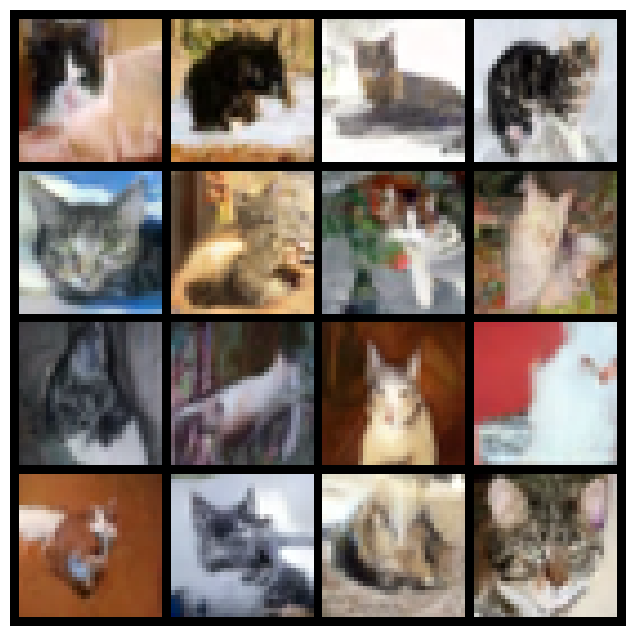

Local results: /kaggle/working/balanced_cat_sde/run_20261022_064721_658725
Persistent backup: None
Wall time including setup: 7.95 hours


In [9]:
try:
    with ema_weights():
        samples=generate(deadline=DEADLINE-30)
        metrics=monitor(completed_updates,deadline=DEADLINE-20)
    torch.save(samples.cpu(),RUN/"cats_raw.pt")
    save_image(samples.clamp(0,1),RUN/"cats_final_seed1234.png",nrow=4)
    monitor_history.extend(metrics)
    (RUN/"monitoring.json").write_text(json.dumps(monitor_history,indent=2))
    if BACKUP is not None:
        for name in ("cats_raw.pt","cats_final_seed1234.png"):
            shutil.copy2(RUN/name,BACKUP/name)
    grid=make_grid(samples.clamp(0,1).cpu(),nrow=4)
    plt.figure(figsize=(8,8));plt.imshow(grid.permute(1,2,0),interpolation="nearest");plt.axis("off");plt.show()
    summary["clipped_pixel_fraction"]=float(((samples<0)|(samples>1)).float().mean())
except TimeoutError as exc:
    print(str(exc),"Training is saved. Use the sampling-only cell below in a later session.")
summary["total_wall_seconds"]=time.monotonic()-NOTEBOOK_START
(RUN/"summary.json").write_text(json.dumps(summary,indent=2));sync_small_files()
print("Local results:",RUN)
print("Persistent backup:",BACKUP)
print(f"Wall time including setup: {summary['total_wall_seconds']/3600:.2f} hours")

## Optional: generate later without retraining
Do not run this cell during normal Run All (`SAMPLE_ONLY=False`). If a session ended before generation, set `SAMPLE_ONLY=True`, point `SAMPLE_CHECKPOINT` at a trusted compatible file, and run only the source/settings/data/functions cells and this cell; skip calibration and timed training. Keep architecture/effective batch consistent. This standalone sampling cell has a 15-minute budget of its own.

In [10]:
SAMPLE_ONLY = False
SAMPLE_CHECKPOINT = None
if SAMPLE_ONLY:
    if SAMPLE_CHECKPOINT is None:raise ValueError("Set SAMPLE_CHECKPOINT")
    completed_updates=restore_checkpoint(SAMPLE_CHECKPOINT)
    with ema_weights():
        samples=generate(deadline=time.monotonic()+15*60)
    save_image(samples.clamp(0,1),RUN/"cats_sample_only.png",nrow=4)
    if BACKUP is not None:shutil.copy2(RUN/"cats_sample_only.png",BACKUP/"cats_sample_only.png")
    print(RUN/"cats_sample_only.png")

## Fidelity, validation and sources
Song et al., arXiv:2011.13456v2, Sections 3-4 and Appendix H: https://arxiv.org/abs/2011.13456 . Official PyTorch code: https://github.com/yang-song/score_sde_pytorch . Source commit is embedded above. Core files: configs/vp/cifar10_ddpmpp_continuous.py, models/ncsnpp.py, models/layerspp.py, models/ema.py, models/utils.py, losses.py, sde_lib.py and sampling.py.

Intentional departures: smaller width/depth; effective batch 64; calibrated shorter warm-up; AMP convolution; GPU-resident independent data sampling; cat-only task; deadline-based stopping and cloud-specific persistence. Adam peak LR, epsilon objective, VP perturbation and solver equations, time embedding conventions and architectural components are retained. No new image-generation method is substituted for the SDE model.

Preparation validates notebook schema/syntax, preset configurations, loss/sampler equivalence, save/load and incompatibility rejection, cat filtering and warm-up calculations on CPU. No T4/Colab training, quality result or guaranteed wall-clock benchmark is claimed. Cloud interruption, slow storage and GPU contention remain outside the notebook's control.